<a href="https://colab.research.google.com/github/User0SE4/Master_VMI_2026_2027_TP_SSL/blob/main/selfsupervised_demos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# References

[Course Webpage](https://sites.google.com/view/berkeley-cs294-158-sp20/home)

[1] Pathak, Deepak, et al. "Context encoders: Feature learning by inpainting." Proceedings of the IEEE conference on computer vision and pattern recognition. 2016.

[2] Gidaris, Spyros, Praveer Singh, and Nikos Komodakis. "Unsupervised representation learning by predicting image rotations." arXiv preprint arXiv:1803.07728 (2018).

[3] Chen, Ting, et al. "A simple framework for contrastive learning of visual representations." arXiv preprint arXiv:2002.05709 (2020).

[4] Noroozi, Mehdi, and Paolo Favaro. "Unsupervised learning of visual representations by solving jigsaw puzzles." European Conference on Computer Vision. Springer, Cham, 2016.

[5] Wang, Xiaolong, Allan Jabri, and Alexei A. Efros. "Learning correspondence from the cycle-consistency of time." Proceedings of the IEEE Conference on Computer Vision and Pattern Recognition. 2019.

[6] Oord, Aaron van den, Yazhe Li, and Oriol Vinyals. "Representation learning with contrastive predictive coding." arXiv preprint arXiv:1807.03748 (2018).

[7] Hénaff, Olivier J., et al. "Data-efficient image recognition with contrastive predictive coding." arXiv preprint arXiv:1905.09272 (2019).

[8] Tian, Yonglong, Dilip Krishnan, and Phillip Isola. "Contrastive multiview coding." arXiv preprint arXiv:1906.05849 (2019).

[9] He, Kaiming, et al. "Momentum contrast for unsupervised visual representation learning." arXiv preprint arXiv:1911.05722 (2019).

[10] Doersch, Carl, Abhinav Gupta, and Alexei A. Efros. "Unsupervised visual representation learning by context prediction." Proceedings of the IEEE International Conference on Computer Vision. 2015.

[11] Ronneberger, Olaf, Philipp Fischer, and Thomas Brox. "U-net: Convolutional networks for biomedical image segmentation." International Conference on Medical image computing and computer-assisted intervention. Springer, Cham, 2015.

# Getting Started
Go to **Runtime -> Change runtime type** and make sure **Hardward accelerator** is set to **GPU**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!ls /content/drive

MyDrive


In [ ]:

root_folder = '/content/drive/MyDrive/MASTER_VMI_2026_2027/APPRENTISSAGE PROFOND POUR LA VISION/TP_Self_Supervised_Learning'#Change this path!!

In [ ]:
import os
# assure que le dossier de sauvegarde existe sur le Drive
os.makedirs(root_folder, exist_ok=True)
print("Folder GDrive pour les sauvegardes :", root_folder)

Folder GDrive pour les sauvegardes : /content/drive/MyDrive/MASTER_VMI_2026_2027/APPRENTISSAGE PROFOND POUR LA VISION/TP_Self_Supervised_Learning


In [ ]:
# Retour à la racine de la machine virtuelle Colab
os.chdir('/content')

In [ ]:
!if [ -d cs294-158-ssl ]; then rm -Rf cs294-158-ssl; fi
!git clone https://github.com/ckurtz/cs294-158-ssl
!pip install cs294-158-ssl/

import os
os.chdir('cs294-158-ssl')
print("Dossier de travail :", os.getcwd())

Cloning into 'cs294-158-ssl'...
remote: Enumerating objects: 615, done.
remote: Counting objects: 100% (98/98), done.
remote: Compressing objects: 100% (8/8), done.
remote: Total 615 (delta 92), reused 90 (delta 90), pack-reused 517 (from 1)
Receiving objects: 100% (615/615), 3.10 MiB | 8.06 MiB/s, done.
Resolving deltas: 100% (442/442), done.
Processing ./cs294-158-ssl
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for deepul_helper: filename=deepul_helper-0.1.0-py3-none-any.whl size=25330 sha256=add818735e6407a13f2aac9ffac6fb7c99131edb19dbe2ddb119b1a9574c1edd
  Stored in directory: /tmp/pip-ephem-wheel-cache-z05qtwh9/wheels/41/c6/8a/07e8f4374eeb04ae58407716e4acc5040e23fe93acd34d166b
Successfully built deepul_helper
Dossier de travail : /content/cs294-158-ssl


Run the cells below to download the necessary pretrained models. It should take a few minutes.

In [ ]:
!wget https://camille-kurtz.com/teaching/data.zip
!unzip -qq data.zip
!rm data.zip

--2026-11-01 11:52:19--  https://camille-kurtz.com/teaching/data.zip
Resolving camille-kurtz.com (camille-kurtz.com)... 213.186.33.3
Connecting to camille-kurtz.com (camille-kurtz.com)|213.186.33.3|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 4227668031 (3.9G) [application/zip]
Saving to: ‘data.zip’

data.zip            100%[===================>]   3.94G  25.6MB/s    in 4m 40s  

2026-11-01 11:57:01 (14.4 MB/s) - ‘data.zip’ saved [4227668031/4227668031]



In [ ]:
!wget https://camille-kurtz.com/teaching/results.zip
!unzip -qq results.zip
!rm results.zip

--2026-11-01 11:57:54--  https://camille-kurtz.com/teaching/results.zip
Resolving camille-kurtz.com (camille-kurtz.com)... 213.186.33.3
Connecting to camille-kurtz.com (camille-kurtz.com)|213.186.33.3|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 2636425194 (2.5G) [application/zip]
Saving to: ‘results.zip’

results.zip         100%[===================>]   2.46G  12.5MB/s    in 5m 7s   

2026-11-01 12:03:02 (8.20 MB/s) - ‘results.zip’ saved [2636425194/2636425194]



The models and demos shown were pre-trained. The code used for all the demos can be found in the github repo [here](https://github.com/wilson1yan/cs294-158-ssl). Follow the README to train models on CIFAR10 or ImageNet.

# Self-Supervised Learning Tasks
Self-supervised learning is a rapidly growing field, its success largely accelerated by growing compute and the vast amount of unlabeled data available for training. The hope is that by pretraining on specially designed self-supervised tasks, the models would be able to learn semantically meaningful representations to be used for downstream tasks. In the following demos, we will look at a few examples of these self-supervised tasks.

In [ ]:
from deepul_helper.demos import load_model_and_data, evaluate_accuracy, display_nearest_neighbors, show_context_encoder_inpainting

%matplotlib inline

## Demo 1: Context Encoder [[1]](https://arxiv.org/abs/1604.07379)

The context encoder structures its self-supervised learning task by inpainting masked images. For example, the figure below shows different masking shapes, such as center masking, random block masking, and segmentation masking. Note that segmentation masking (c) is not purely self-supervised since we would need to train a image segmentation model which requires labels. However, the other two masking schemes (a) and (b) and purely self-supervised.

![](https://drive.google.com/uc?id=1fhzkULYTtyMGUUF2n9dlPayJSdcY5pRv)

More formally, the context encoder optimizes the following reconstruction loss:
$$\mathcal{L}_{rec} = \left\Vert \hat{M} \odot (x - F((1 - \hat{M})\odot x)) \right\Vert^2_2$$
where $\hat{M}$ is the masked region, $x$ is the image, and $F$ is the context encoder that tries to reconstruct the masked portion. In addition to the reconstruction loss, the paper introduces an adversarial loss that encourages more realistic inpaintings.
$$L_{adv} = \max_D \mathbb{E}_{x\in \chi} [\log(D(x)) + \log(1 - D(F((1-\hat{M})\odot x)))]$$
However, this demo does not use the adversarial portion of the loss.

### Example Code

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F


class ContextEncoder(nn.Module):
    metrics = ['Loss']
    metrics_fmt = [':.4e']

    def __init__(self, dataset, n_classes):
        super().__init__()
        input_channels = 3

        self.latent_dim = 4000

        # Encodes the masked image
        self.encoder = nn.Sequential(
            # 128 x 128 Input
            nn.Conv2d(input_channels, 64, 4, stride=2, padding=1), # 64 x 64
            nn.BatchNorm2d(64),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(64, 64, 4, stride=2, padding=1), # 32 x 32
            nn.BatchNorm2d(64),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(64, 128, 4, stride=2, padding=1), # 16 x 16
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(128, 256, 4, stride=2, padding=1), # 8 x 8
            nn.BatchNorm2d(256),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(256, 512, 4, stride=2, padding=1), # 4 x 4
            nn.BatchNorm2d(512),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(512, self.latent_dim, 4) # 1 x 1
        )

        # Only reconstructs the masked part of the image and not the whole image
        self.decoder = nn.Sequential(
           nn.BatchNorm2d(self.latent_dim),
           nn.ReLU(inplace=True),
           nn.ConvTranspose2d(self.latent_dim, 512, 4, stride=1, padding=0), # 4 x 4
           nn.BatchNorm2d(512),
           nn.ReLU(inplace=True),
           nn.ConvTranspose2d(512, 256, 4, stride=2, padding=1), # 8 x 8
           nn.BatchNorm2d(256),
           nn.ReLU(inplace=True),
           nn.ConvTranspose2d(256, 128, 4, stride=2, padding=1), # 16 x 16
           nn.BatchNorm2d(128),
           nn.ReLU(inplace=True),
           nn.ConvTranspose2d(128, 64, 4, stride=2, padding=1), # 32 x 32
           nn.BatchNorm2d(64),
           nn.ReLU(inplace=True),
           nn.ConvTranspose2d(64, input_channels, 4, stride=2, padding=1), # 64 x 64
           nn.Tanh()
        )

        self.dataset = dataset
        self.n_classes = n_classes

    def construct_classifier(self):
        classifier = nn.Sequential(
            nn.Flatten(),
            nn.BatchNorm1d(self.latent_dim, affine=False),
            nn.Linear(self.latent_dim, self.n_classes)
        )
        return classifier

    def forward(self, images):
        # Extract a 64 x 64 center from 128 x 128 image
        images_center = images[:, :, 32:32+64, 32:32+64].clone()
        images_masked = images.clone()
        # Mask out a 64 x 64 center with slight overlap
        images_masked[:, 0, 32+4:32+64-4, 32+4:32+64-4] = 2 * 117.0/255.0 - 1.0
        images_masked[:, 1, 32+4:32+64-4, 32+4:32+64-4] = 2 * 104.0/255.0 - 1.0
        images_masked[:, 2, 32+4:32+64-4, 32+4:32+64-4] = 2 * 123.0/255.0 - 1.0

        z = self.encoder(images_masked)
        center_recon = self.decoder(z)

        return dict(Loss=F.mse_loss(center_recon, images_center)), torch.flatten(z, 1)

    def encode(self, images):
        images_masked = images
        images_masked[:, 0, 32+4:32+64-4, 32+4:32+64-4] = 2 * 117.0/255.0 - 1.0
        images_masked[:, 1, 32+4:32+64-4, 32+4:32+64-4] = 2 * 104.0/255.0 - 1.0
        images_masked[:, 2, 32+4:32+64-4, 32+4:32+64-4] = 2 * 123.0/255.0 - 1.0
        return self.encoder(images_masked)

    def reconstruct(self, images):
        images_center = images[:, :, 32:32+64, 32:32+64].clone()
        images_masked = images.clone()
        images_masked[:, 0, 32+4:32+64 - 4, 32+4:32+64-4] = 2 * 117.0/255.0 - 1.0
        images_masked[:, 1, 32+4:32+64 - 4, 32+4:32+64-4] = 2 * 104.0/255.0 - 1.0
        images_masked[:, 2, 32+4:32+64 - 4, 32+4:32+64-4] = 2 * 123.0/255.0 - 1.0

        z = self.encoder(images_masked)
        center_recon = self.decoder(z)

        images_recon = images_masked.clone()
        images_recon[:, :, 32:32+64, 32:32+64] = center_recon
        return images_masked, images_recon


### Inpainting Examples
For each pair of images, the left image is the masked input and the right the inpainted reconstruction.

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


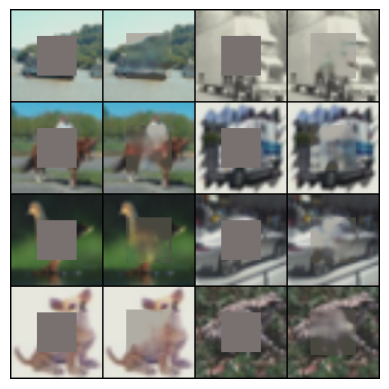

In [ ]:
show_context_encoder_inpainting()

### Linear Classification
By design the model architecture is an encoder -> decoder module. We can use the bottleneck layer as our learned representation. Below, we show linear classification accuracy results on CIFAR10 using the learned representations.

In [ ]:
model, linear_classifier, train_loader, test_loader = load_model_and_data('context_encoder')
#evaluate_accuracy(model, linear_classifier, train_loader, test_loader)

In [ ]:
from deepul_helper.demos import evaluate_classifier
# Context Encoder
train_acc1, train_acc5 = evaluate_classifier(model, linear_classifier, train_loader)
test_acc1, test_acc5 = evaluate_classifier(model, linear_classifier, test_loader)

accuracy_context_encoder = {
    'train_top1': train_acc1,
    'train_top5': train_acc5,
    'test_top1': test_acc1,
    'test_top5': test_acc5
}

print("Context Encoder")
print(accuracy_context_encoder)

Context Encoder
{'train_top1': 53.236, 'train_top5': 94.094, 'test_top1': 45.77, 'test_top5': 90.29}


### Nearest Neighbors
Another way to evaluate our learned representation is to look at nearest neighbors to random encoded images in latent space.

Image 1


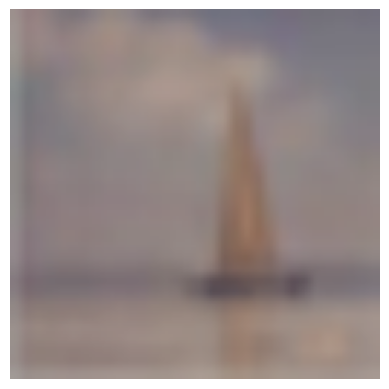

Top 16 Nearest Neighbors (in latent space)


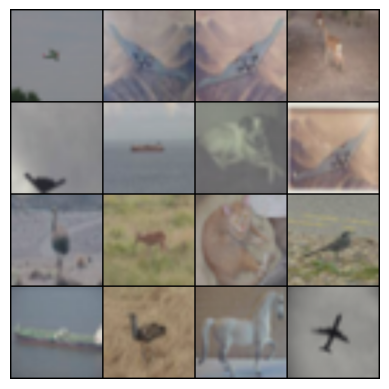

Image 2


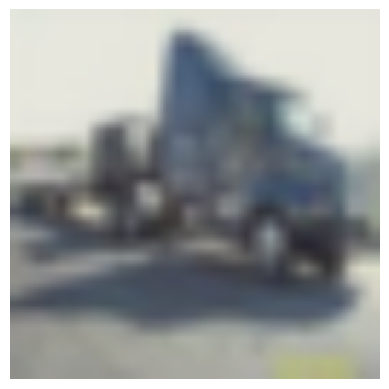

Top 16 Nearest Neighbors (in latent space)


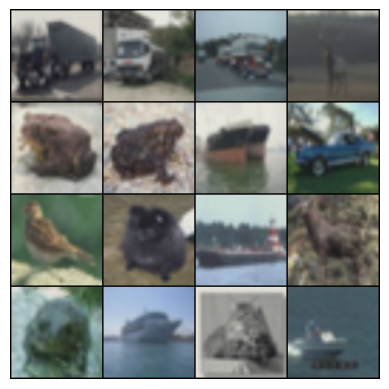

Image 3


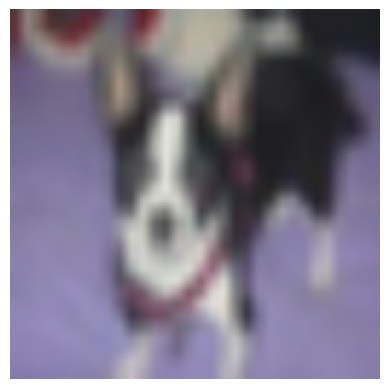

Top 16 Nearest Neighbors (in latent space)


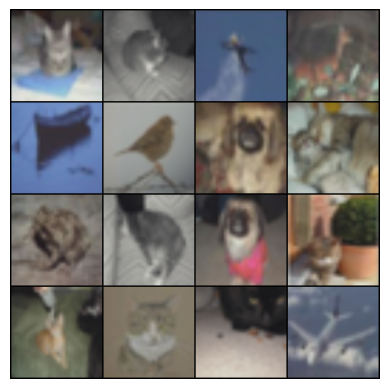

Image 4


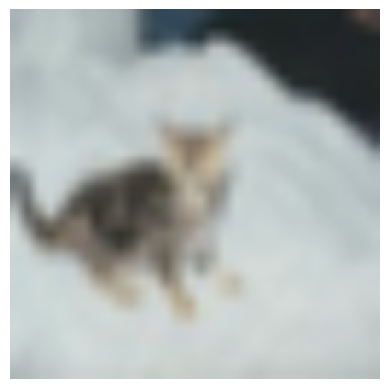

Top 16 Nearest Neighbors (in latent space)


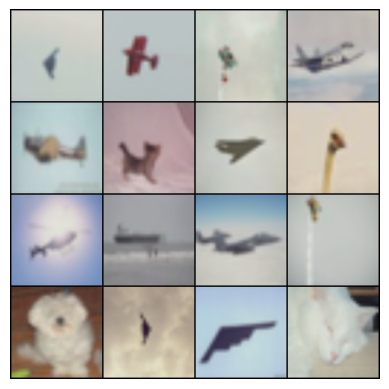

In [ ]:
display_nearest_neighbors('context_encoder', model, test_loader)

## Demo 2: Rotation Prediction [[2]](https://arxiv.org/abs/1803.07728)

In this paper, the authors show that accurately predicting the degrees of rotation in images is a self-supervised learning task that learns good representations for downstream tasks.

![](https://drive.google.com/uc?id=1eHXLH-N_6uMGRzdf1Wjnga26qlS5-FRv)

More specifically, the authors showed that training a common CNN architecture (AlexNet, ResNet) on the rotation task learns semantically interpretable convolutional masks similar to those learned in supervised learning.

### Example Code

In [ ]:
import math

import torch
import torch.nn as nn
import torch.nn.functional as F


class RotationPrediction(nn.Module):
    metrics = ['Loss', 'Acc1']
    metrics_fmt = [':.4e', ':6.2f']

    def __init__(self, dataset, n_classes):
        super().__init__()
        if dataset == 'cifar10':
            self.model = NetworkInNetwork()  #CNN utilisé
            self.latent_dim = 192 * 8 * 8
            self.feat_layer = 'conv2'
        elif 'imagenet' in dataset:
            self.model = AlexNet()
            self.latent_dim = 256 * 13 * 13
            self.feat_layer = 'conv5'
        else:
            raise Exception('Unsupported dataset:', dataset)
        self.dataset = dataset
        self.n_classes = n_classes

    def construct_classifier(self):
        if self.dataset == 'cifar10':
            classifier = nn.Sequential(
                Flatten(),
                nn.BatchNorm1d(self.latent_dim, affine=False),
                nn.Linear(self.latent_dim, self.n_classes)
            )
        elif 'imagenet' in self.dataset:
            classifier = nn.Sequential(
                nn.AdaptiveMaxPool2d((6, 6)),
                nn.BatchNorm2d(256, affine=False),
                Flatten(),
                nn.Linear(256 * 6 * 6, self.n_classes)
            )
        else:
            raise Exception('Unsupported dataset:', dataset)
        return classifier

    def forward(self, images):
        batch_size = images.shape[0]
        images, targets = self._preprocess(images)
        targets = targets.to(images.get_device())

        logits, zs = self.model(images, out_feat_keys=('classifier', self.feat_layer))
        loss = F.cross_entropy(logits, targets)

        pred = logits.argmax(dim=-1)
        correct = pred.eq(targets).float().sum()
        acc = correct / targets.shape[0] * 100.

        return dict(Loss=loss, Acc1=acc), zs[:batch_size]

    def encode(self, images):
        zs = self.model(images, out_feat_keys=(self.feat_layer,))
        return zs

    def _preprocess(self, images):
        batch_size = images.shape[0]
        images_90 = torch.flip(images.transpose(2, 3), (2,))
        images_180 = torch.flip(images, (2, 3))
        images_270 = torch.flip(images, (2,)).transpose(2, 3)
        images_batch = torch.cat((images, images_90, images_180, images_270), dim=0)
        targets = torch.arange(4).long().repeat(batch_size) # Génération automatique des labels (64 occurences de chaque label)
        targets = targets.view(batch_size, 4).transpose(0, 1)
        targets = targets.contiguous().view(-1)
        return images_batch, targets

### Linear Classification
We can use the feature maps in the later convolutional layers of the pretrained model as our learned representation for linear classification.

In [ ]:
model, linear_classifier, train_loader, test_loader = load_model_and_data('rotation')
#evaluate_accuracy(model, linear_classifier, train_loader, test_loader)

In [ ]:
# Rotation Prediction
train_acc1, train_acc5 = evaluate_classifier(model, linear_classifier, train_loader)
test_acc1, test_acc5 = evaluate_classifier(model, linear_classifier, test_loader)

accuracy_rotation = {
    'train_top1': train_acc1,
    'train_top5': train_acc5,
    'test_top1': test_acc1,
    'test_top5': test_acc5
}

print("Rotation Prediction")
print(accuracy_rotation)

Rotation Prediction
{'train_top1': 79.41, 'train_top5': 99.1, 'test_top1': 79.91, 'test_top5': 99.12}


### Nearest Neighbors
Another way to evaluate our learned representation is to look at nearest neighbors to random encoded images in latent space.

Image 1


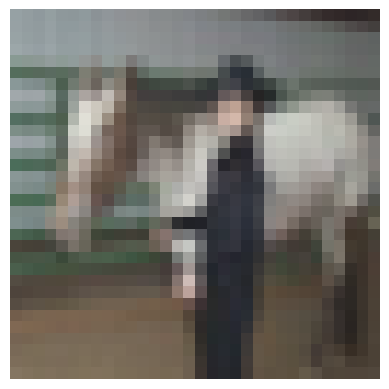

Top 16 Nearest Neighbors (in latent space)


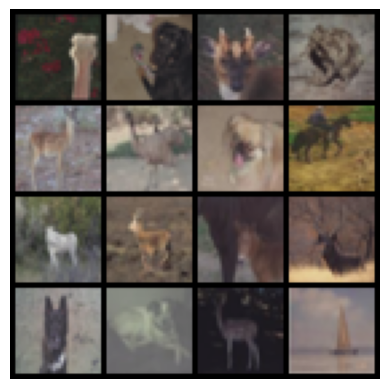

Image 2


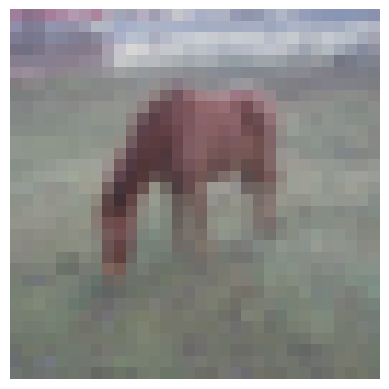

Top 16 Nearest Neighbors (in latent space)


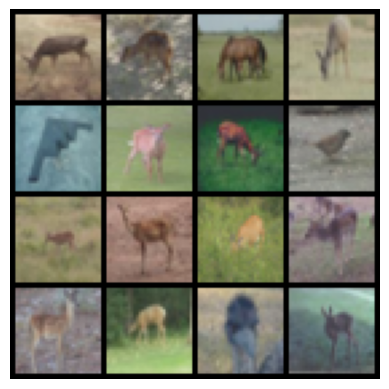

Image 3


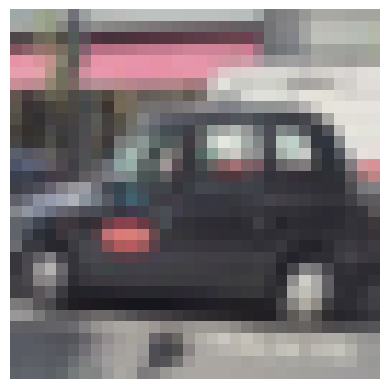

Top 16 Nearest Neighbors (in latent space)


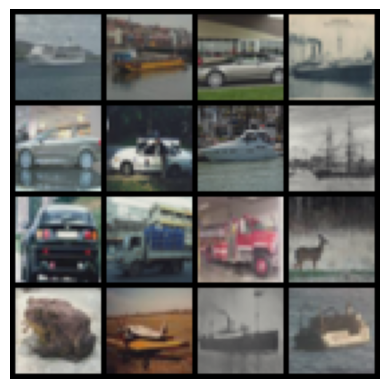

Image 4


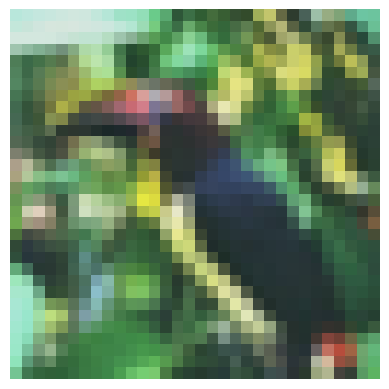

Top 16 Nearest Neighbors (in latent space)


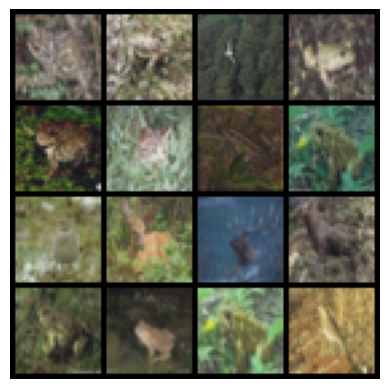

In [ ]:
display_nearest_neighbors('rotation', model, test_loader)

## Demo 3: SimCLR [[3]](https://arxiv.org/abs/2002.05709)

SimCLR is a contrastive learning framework to learn strong visual representations. An image $x$ is processed using data augmentation to produce two variants $x_i$ and $x_j$ which are both fed into encoder $f$ (a CNN) and projection head $g$ (a small MLP). The models optimize a contrastive loss to maximally align projected latents $z_i, z_j$. We consider $x_i, x_j$ as a positive pair, and any other $x_i, x_k$ pairs (i.e. different images in the same batch) are negative pairs. A visual diagram of the training procedure is shown below (from the paper).

![](https://drive.google.com/uc?id=1XW1uIkUTMSa0DZncivSYXzM5gA5FIhF6)

More formally, the loss between positive example $z_i, z_j$ is:
$$\ell_{i,j} = -\log{\frac{\exp(\text{sim}(z_i, z_j)/\tau)}{\sum_{k=1}^{2N}\mathbb{1}_{[k\neq i]}\exp(\text{sim}(z_i, z_k)/\tau)}}$$
where $\text{sim}(z_i, z_j) = z_i^Tz_j / (\left\Vert z_i \right\Vert \left\Vert z_j \right\Vert)$. The loss function can also be interpreted as a standard cross entropy loss to classify positive samples where logits are constructed using a given similarity function.

Note: A common idea in contrastive learning methods is that a larger batch means more negative samples. Therefore, these methods usually benefit the most from large-batch learning compared to other self-supervised learning tasks.

### Example Code

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

from deepul_helper.resnet import resnet_v1
from deepul_helper.batch_norm import SyncBatchNorm, BatchNorm1d

# Some code adapted from https://github.com/sthalles/SimCLR
class SimCLR(nn.Module):
    metrics = ['Loss']
    metrics_fmt = [':.4e']

    def __init__(self, dataset, n_classes, dist=None):
        super().__init__()
        self.temperature = 0.5
        self.projection_dim = 128

        if dataset == 'cifar10':
            resnet = resnet_v1((3, 32, 32), 50, 1, cifar_stem=True)
            resnet = SyncBatchNorm.convert_sync_batchnorm(resnet)
            self.resnet = resnet
            self.latent_dim = 2048
        elif 'imagenet' in dataset:
            resnet = resnet_v1((3, 128, 128), 50, 1, cifar_stem=False)
            if dist is not None:
                resnet = nn.SyncBatchNorm.convert_sync_batchnorm(resnet)
            self.resnet = resnet
            self.latent_dim = 2048
#Projection Head
        self.proj = nn.Sequential(
            nn.Linear(self.latent_dim, self.projection_dim, bias=False),
            BatchNorm1d(self.projection_dim),
            nn.ReLU(inplace=True),
            nn.Linear(self.projection_dim, self.projection_dim, bias=False),
            BatchNorm1d(self.projection_dim, center=False)
        )

        self.dataset = dataset
        self.n_classes = n_classes
        self.dist = dist

    def construct_classifier(self):
        return nn.Sequential(nn.Linear(self.latent_dim, self.n_classes))

    def forward(self, images):
        n = images[0].shape[0]
        xi, xj = images
        hi, hj = self.encode(xi), self.encode(xj) # (N, latent_dim)
        zi, zj = self.proj(hi), self.proj(hj) # (N, projection_dim)
        zi, zj = F.normalize(zi), F.normalize(zj)

        # Each training example has 2N - 2 negative samples
        # 2N total samples, but exclude the current and positive sample

        if self.dist is None:
            zis = [zi]
            zjs = [zj]
        else:
            zis = [torch.zeros_like(zi) for _ in range(self.dist.get_world_size())]
            zjs = [torch.zeros_like(zj) for _ in range(self.dist.get_world_size())]

            self.dist.all_gather(zis, zi)
            self.dist.all_gather(zjs, zj)

        z1 = torch.cat((zi, zj), dim=0) # (2N, projection_dim)
        z2 = torch.cat(zis + zjs, dim=0) # (2N * n_gpus, projection_dim)

        sim_matrix = torch.mm(z1, z2.t()) # (2N, 2N * n_gpus)
        sim_matrix = sim_matrix / self.temperature
        # Mask out same-sample terms
        n_gpus = 1 if self.dist is None else self.dist.get_world_size()
        rank = 0 if self.dist is None else self.dist.get_rank()
        sim_matrix[torch.arange(n), torch.arange(rank*n, (rank+1)*n)]  = -float('inf')
        sim_matrix[torch.arange(n, 2*n), torch.arange((n_gpus+rank)*n, (n_gpus+rank+1)*n)] = -float('inf')

        targets = torch.cat((torch.arange((n_gpus+rank)*n, (n_gpus+rank+1)*n),
                             torch.arange(rank*n, (rank+1)*n)), dim=0)
        targets = targets.to(sim_matrix.get_device()).long()

        loss = F.cross_entropy(sim_matrix, targets, reduction='sum')
        loss = loss / n
        return dict(Loss=loss), hi

    def encode(self, images):
        return self.resnet(images[0])

    def get_features(self, images):
        return self.resnet.get_features(images)


### Linear Classification
We can use the encoded vector $h_i$ as our latent representation.

In [ ]:
model, linear_classifier, train_loader, test_loader = load_model_and_data('simclr')
#evaluate_accuracy(model, linear_classifier, train_loader, test_loader)

In [ ]:
# SimCLR
train_acc1, train_acc5 = evaluate_classifier(model, linear_classifier, train_loader)
test_acc1, test_acc5 = evaluate_classifier(model, linear_classifier, test_loader)

accuracy_simclr = {
    'train_top1': train_acc1,
    'train_top5': train_acc5,
    'test_top1': test_acc1,
    'test_top5': test_acc5
}

print("SimCLR")
print(accuracy_simclr)

SimCLR
{'train_top1': 89.938, 'train_top5': 99.444, 'test_top1': 92.84, 'test_top5': 99.86}


### Nearest Neighbors
Another way to evaluate our learned representation is to look at nearest neighbors to random encoded images in latent space.

Image 1


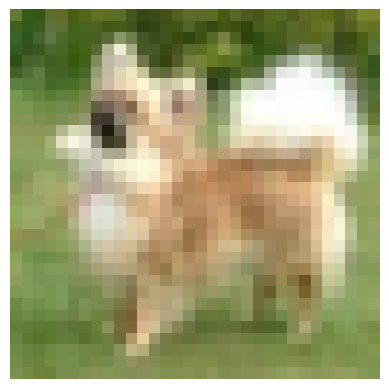

Top 16 Nearest Neighbors (in latent space)


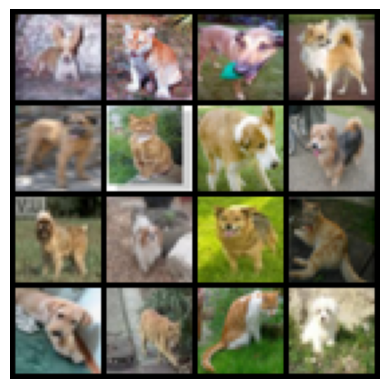

Image 2


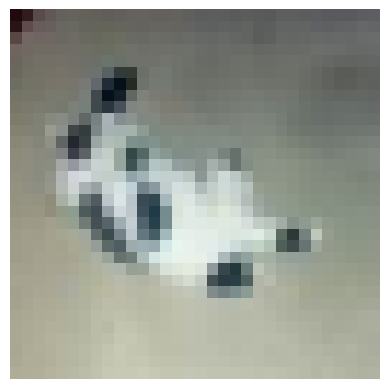

Top 16 Nearest Neighbors (in latent space)


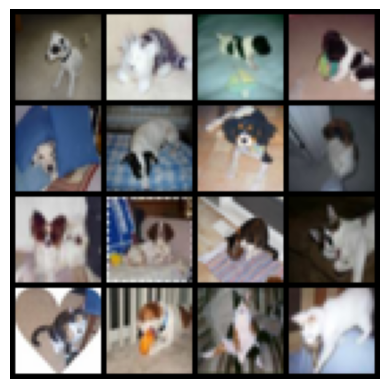

Image 3


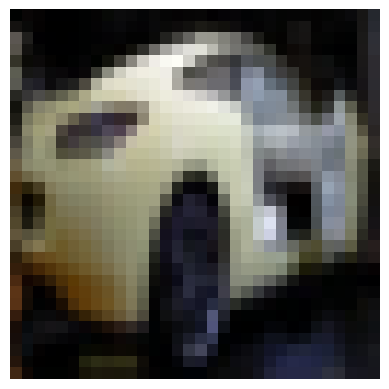

Top 16 Nearest Neighbors (in latent space)


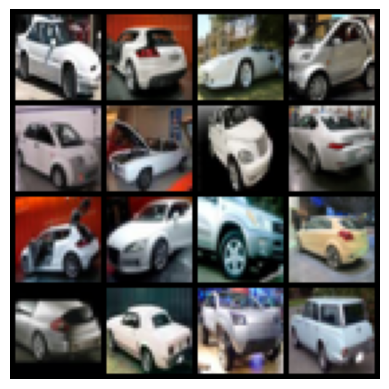

Image 4


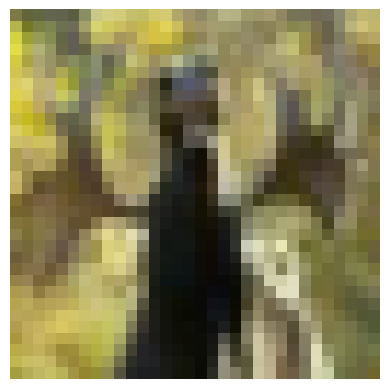

Top 16 Nearest Neighbors (in latent space)


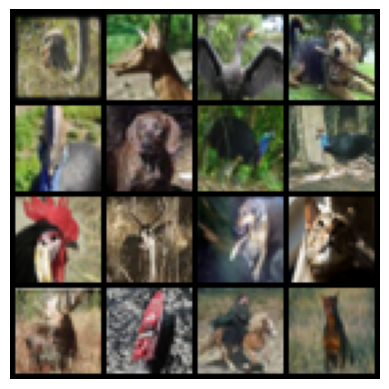

In [ ]:
display_nearest_neighbors('simclr', model, test_loader)

## Other Tasks
In addition to the above tasks, prior work has also investigated other self-superivsed tasks such as solving jigsaw puzzles [[4]](https://arxiv.org/abs/1603.09246), cycle-consistency [[5]](https://arxiv.org/abs/1903.07593), contrastive learning [[6]](https://arxiv.org/abs/1807.03748)[[7]](https://arxiv.org/abs/1905.09272)[[8]](https://arxiv.org/abs/1906.05849)[[9]](https://arxiv.org/abs/1911.05722), and patch prediction [[10]](https://arxiv.org/abs/1505.05192). See [here](https://github.com/jason718/awesome-self-supervised-learning) for a great resource on more self-supervised learning papers.

# Demo 4: Using Representations for Downstream Tasks

After pretraining a model on a self-supervised learning task, we can use it for other downstream tasks. In this demo, we use the pre-trained ResNet50 backbone from training SimCLR on a subset of ImageNet to learn a semantic segmentation model on Pascal VOC 2012. We use a simple U-Net [[11]](https://arxiv.org/abs/1505.04597) architecture with skip connections across feature maps between the SimCLR encoder and learned upsampling decoder. We do not fine-tune the SimCLR ResNet50 backbone, and only optimize the upsampling portion.

![](https://drive.google.com/uc?id=19dxxcwof0IA0jyv0VCl4rnZZf3ajA22s)

The training script can be found in `train_segmentation.py` [here](https://github.com/wilson1yan/cs294-158-ssl/blob/master/train_segmentation.py).

## Example Code

In [ ]:
# Code adapted from https://github.com/qubvel/segmentation_models.pytorch

import torch
import torch.nn as nn
import torch.nn.functional as F
from deepul_helper.resnet import NormReLU

class SegmentationModel(nn.Module):
    metrics = ['Loss']
    metrics_fmt = [':.4e']

    def __init__(self, n_classes):
        super().__init__()

        decoder_channels = (512, 256, 128, 64, 32)
        encoder_channels = (2048, 1024, 512, 256, 64) # Starting from head (resnet 50)

        # Construct decoder blocks
        in_channels = [encoder_channels[0]] + list(decoder_channels[:-1])
        skip_channels = list(encoder_channels[1:]) + [0]
        out_channels = decoder_channels
        blocks = [
            DecoderBlock(in_ch, skip_ch, out_ch)
            for in_ch, skip_ch, out_ch in zip(in_channels, skip_channels, out_channels)
        ]
        self.dec_blocks = nn.ModuleList(blocks)

        # Segmentation head for output prediction
        self.seg_head = nn.Conv2d(decoder_channels[-1], n_classes, kernel_size=3, padding=1)

    def forward(self, features, targets):
        features = features[1:] # remove first skip with same spatial resolution
        features = features[::-1] # reverse channels to start from head of encoder

        skips = features[1:]
        x = features[0]
        for i, decoder_block in enumerate(self.dec_blocks):
            skip = skips[i] if i < len(skips) else None
            x = decoder_block(x, skip)

        logits = self.seg_head(x)
        loss = F.cross_entropy(logits, targets)

        return dict(Loss=loss), logits


class DecoderBlock(nn.Module):
    def __init__(
            self,
            in_channels,
            skip_channels,
            out_channels,
    ):
        super().__init__()
        self.conv1 = nn.Sequential(
            nn.Conv2d(in_channels + skip_channels, out_channels,
                      kernel_size=3, padding=1),
            NormReLU((out_channels, None, None)), # only care about channel dim for BN
        )
        self.conv2 = nn.Sequential(
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            NormReLU((out_channels, None, None))
        )

    def forward(self, x, skip=None):
        x = F.interpolate(x, scale_factor=2, mode="nearest")
        if skip is not None:
            x = torch.cat([x, skip], dim=1)
        x = self.conv1(x)
        x = self.conv2(x)
        return x

## Segmentation Results
Below, we show a random subset of segmentations from the trained model. Every set of 3 images consists of the original image, the labeled segmentation, and the predicted segmentation.

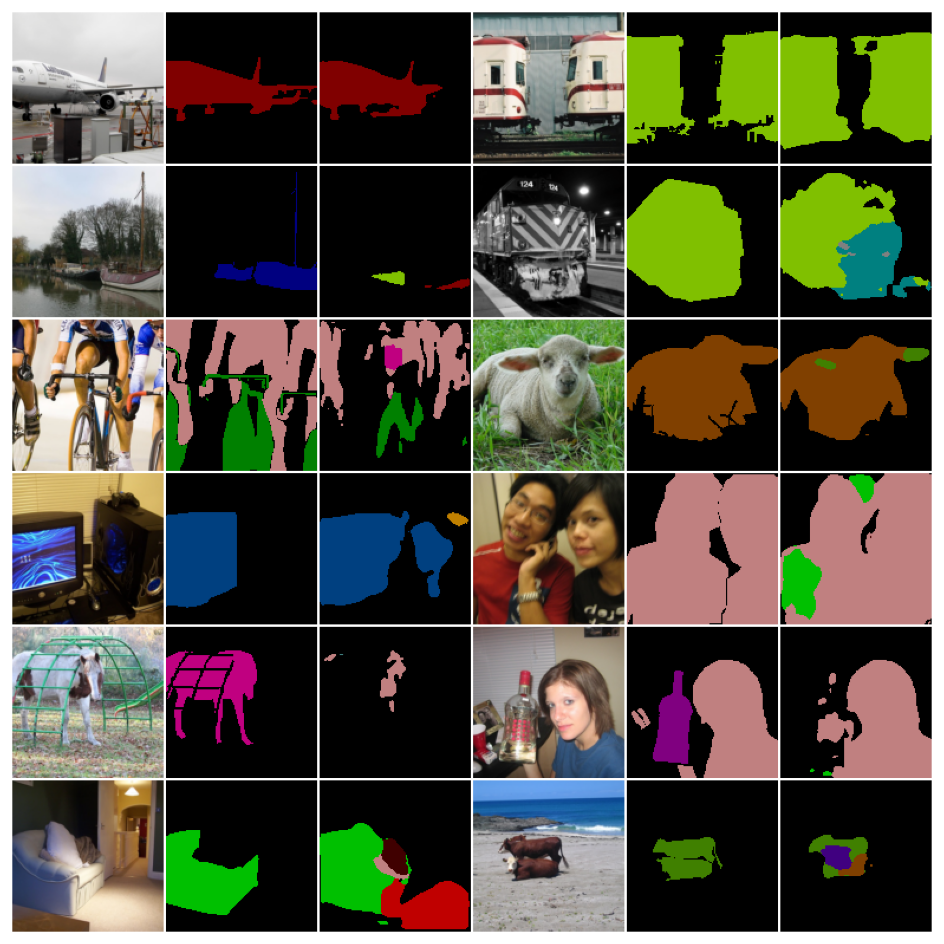

In [ ]:
from deepul_helper.demos import show_segmentation
show_segmentation()

# Demo 5: Avoiding Trivial Representations in Self-Supervised Tasks

When designing a self-supervised learning task, it is important to make sure that no trivial solutions exists. In general, a learned solution is trivial if the model is able to successfully complete its task by taking advantage of low-level features. As a result, it doesn't learn a good representation so downstream performance is bad.

For example, in the jigsaw [[4]](https://arxiv.org/abs/1603.09246) task, a model can "cheat" by just looking at the boundary textures of the jigsaw pieces, or following and matching straight lines across different pieces. These issues can generally be fixed by ranndom cropping, shifting, and spacially jittering.

We look at two other less obvious aspects of images that may reduce performance.

## Chromatic Aberration

Chromatic aberration occurs when the different focal lengths of light results in the light not meeting all at the same point.
![from wikipedia](https://drive.google.com/uc?id=1PYGoQWnH0aAeiE_8t4ef5WDcq1UIQQ5t)

A example of very apparent chromatic aberration is shown below, where the green and magenta colors are clearly offset with each other:

![](https://drive.google.com/uc?id=1M1B6kV6ddBwyJse3FQT8_XBTeqs5s5WL)

Chromatic aberration generally becomes a problem in patch-based self-supervised learning tasks that design, such as solving jigsaw puzzles, or predicintg the correct location of a patch in an image In this case, the model can take advantage of the low-level chromatic aberration features to get a strong idea of where the patch is located without understanding the actual context.

Below is a quick demo of chromatic aberration in more realistic images, and possible fixes. Note that in general, chromatic aberration is fairly hard to spot with the naked eye, but deep learning models are still able to use it to their advantage.

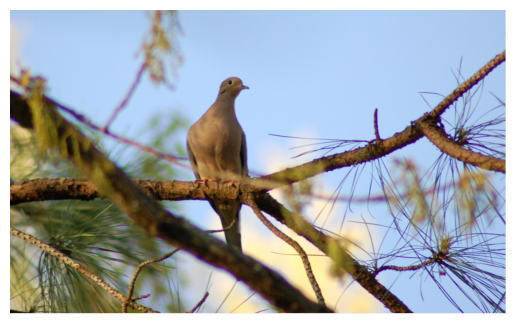

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

# You can see some chromatic aberration in the purple fringes around the branches

image = Image.open('sample_images/chrom_ab_demo.png')
plt.figure()
plt.axis('off')
plt.imshow(image)
plt.show()

Chromatic aberration is generally fixed through conversion to grayscale, or color dropping. Color dropping works by dropping 2 of the color channels and replacing them with random noise uniform or Gaussian noise.

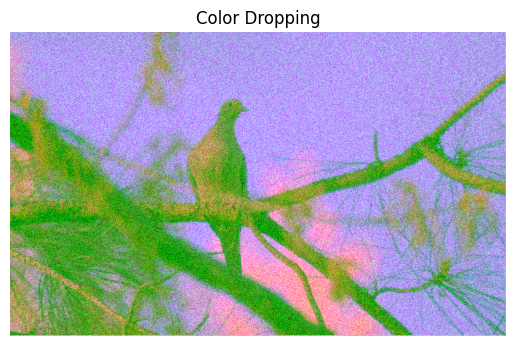

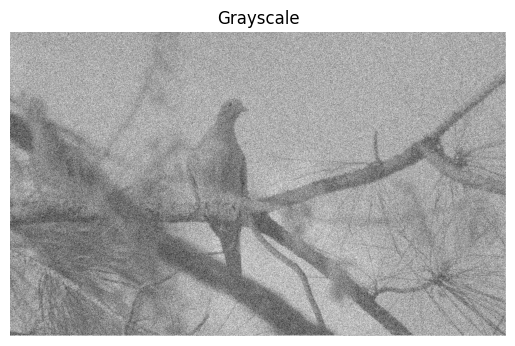

In [ ]:
import numpy as np

# Color Dropping
# We will drop all channels except R
image_cpy = image.copy()
pixels = image_cpy.load()

arr = np.array(image_cpy)
std_R = np.std(arr[:, :, 0])
mean_G, mean_B = np.mean(arr[:, :, 1]), np.mean(arr[:, :, 2])

for i in range(image.size[0]):
  for j in range(image.size[1]):
    p = pixels[i, j] # (R, G, B, A)
    R, A = p[0], p[3]
    G = int(np.random.randn() * std_R + mean_G)
    B = int(np.random.randn() * std_R + mean_B)
    pixels[i, j] = (R, G, p[2], p[3])

plt.figure()
plt.title('Color Dropping')
plt.axis('off')
plt.imshow(image_cpy)
plt.show()

# Grayscale
image_cpy2 = image.copy()
pixels2 = image_cpy2.load()

for i in range(image.size[0]):
  for j in range(image.size[1]):
    p = pixels[i, j]
    G = int(0.3 * p[0] + 0.59 * p[1] + 0.11 * p[2])
    pixels2[i, j] = (G, G, G, 255)

plt.figure()
plt.title('Grayscale')
plt.axis('off')
plt.imshow(image_cpy2)
plt.show()

## Color Intensity Histograms

In the SimCLR paper, the authors show that the histogram of color intensities of different patches within the same image have very similar histograms, which may degrade training by encouraging models to look at low-level (pixel intensity) features to solve self-supervised tasks that involve matching positive patches of the same image.

Below, we run a similar demo to what was demonstrated in the paper

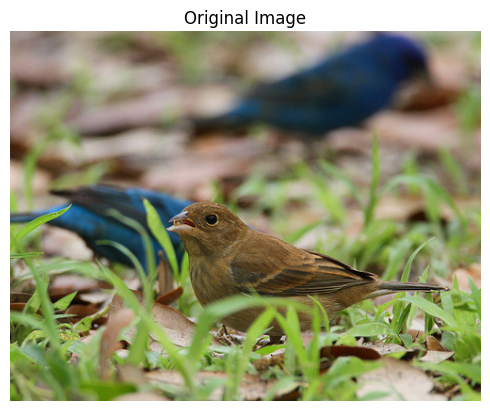

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

image = Image.open('sample_images/n01537544_19414.JPEG')
plt.figure()
plt.title('Original Image')
plt.axis('off')
plt.imshow(image)
plt.show()

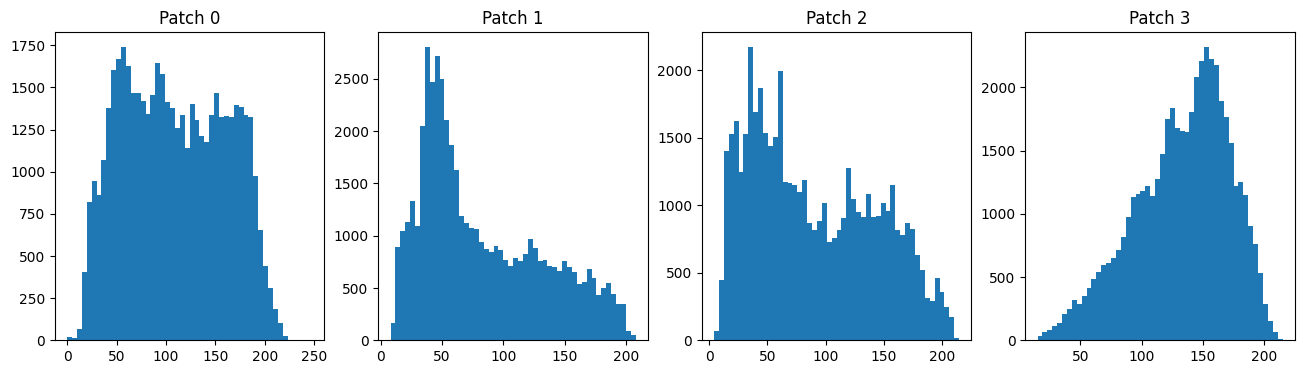

In [ ]:
import numpy as np
arr = np.array(image)
H, W, _ = arr.shape

fig, axs = plt.subplots(1, 4, figsize=(16, 4))
for i in range(4):
  r = np.random.randint(0, H - 128)
  c = np.random.randint(0, W - 128)
  patch = arr[r:r+128, c:c+128]

  axs[i].set_title(f'Patch {i}')
  axs[i].hist(patch.reshape(-1), bins=50)
plt.show()

Now we apply color jittering to mitigate this effect

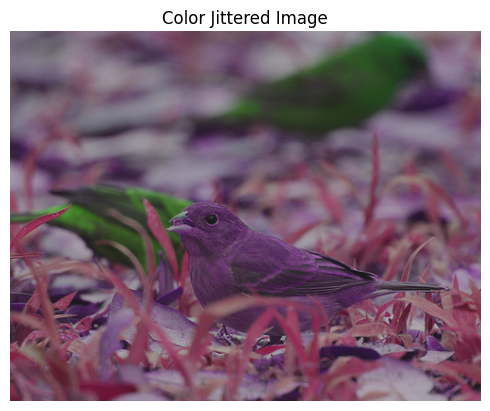

In [ ]:
from torchvision import transforms

color_jitter = transforms.ColorJitter(0.3, 0.3, 0.3, 0.3)
jitter_img = color_jitter(image)

image = Image.open('sample_images/n01537544_19414.JPEG')
plt.figure()
plt.title('Color Jittered Image')
plt.axis('off')
plt.imshow(jitter_img)
plt.show()

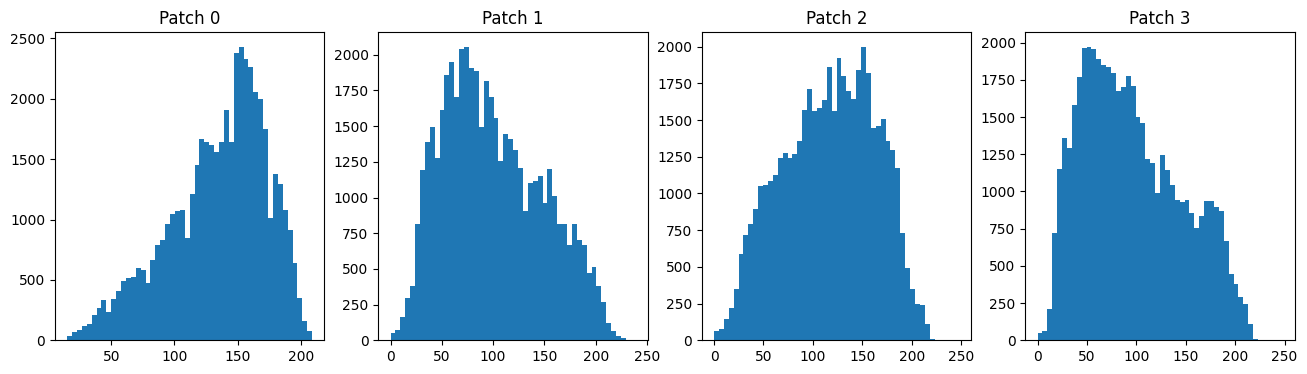

In [ ]:
arr = np.array(image)
H, W, _ = arr.shape

fig, axs = plt.subplots(1, 4, figsize=(16, 4))
for i in range(4):
  r = np.random.randint(0, H - 128)
  c = np.random.randint(0, W - 128)
  patch = arr[r:r+128, c:c+128]

  axs[i].set_title(f'Patch {i}')
  axs[i].hist(patch.reshape(-1), bins=50)
plt.show()

**Comparaison des performances des Démo 1, 2, 3**





In [ ]:
import pandas as pd

results = {
    'Context Encoder': accuracy_context_encoder,
    'Rotation Prediction': accuracy_rotation,
    'SimCLR': accuracy_simclr
}

df = pd.DataFrame(results).T
df.index.name = 'Model'

display(df.round(2))

,train_top1,train_top5,test_top1,test_top5
Model,,,,
Context Encoder,53.24,94.09,45.77,90.29
Rotation Prediction,79.41,99.10,79.91,99.12
SimCLR,89.94,99.44,92.84,99.86


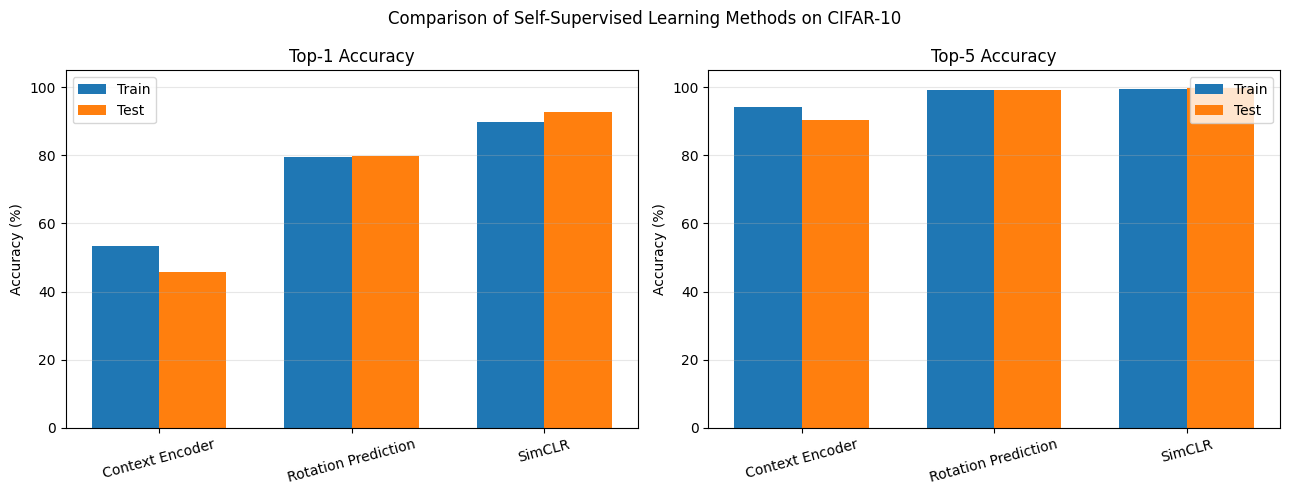

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

models = df.index.tolist()
x = np.arange(len(models))
width = 0.35

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Top-1 Accuracy
axes[0].bar(x - width/2, df['train_top1'], width, label='Train')
axes[0].bar(x + width/2, df['test_top1'], width, label='Test')

axes[0].set_title('Top-1 Accuracy')
axes[0].set_ylabel('Accuracy (%)')
axes[0].set_xticks(x)
axes[0].set_xticklabels(models, rotation=15)
axes[0].set_ylim(0, 105)
axes[0].legend()
axes[0].grid(axis='y', alpha=0.3)

# Top-5 Accuracy
axes[1].bar(x - width/2, df['train_top5'], width, label='Train')
axes[1].bar(x + width/2, df['test_top5'], width, label='Test')

axes[1].set_title('Top-5 Accuracy')
axes[1].set_ylabel('Accuracy (%)')
axes[1].set_xticks(x)
axes[1].set_xticklabels(models, rotation=15)
axes[1].set_ylim(0, 105)
axes[1].legend()
axes[1].grid(axis='y', alpha=0.3)

plt.suptitle('Comparison of Self-Supervised Learning Methods on CIFAR-10')
plt.tight_layout()

plt.savefig('cifar10_model_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

**Dataset: STL-10**

**Demo 1**

**STL-10 adaptation to allow comparisons with CIFAR-10**

### STL-10 from a single source: Hugging Face `jxie/stl10`

All three STL-10 parts (train, test, unlabeled) are loaded from the same Hugging Face repository.

In [ ]:
from datasets import load_dataset

# Single source for STL-10: Hugging Face "jxie/stl10" (Parquet files)
train_dataset = load_dataset("jxie/stl10", split="train")
test_dataset = load_dataset("jxie/stl10", split="test")
unlabeled_dataset = load_dataset("jxie/stl10", split="unlabeled")

print("Train     :", len(train_dataset))
print("Test      :", len(test_dataset))
print("Unlabeled :", len(unlabeled_dataset))
print(train_dataset.features)
print("Label of the first unlabeled image:", unlabeled_dataset[0]['label'])

README.md:   0%|          | 0.00/1.42k [00:00<?, ?B/s]

data/train-00000-of-00001-d61fb57b85a49f(…): reconstructing file:   0%|          |  0.00B / 88.8MB            

data/train-00000-of-00001-d61fb57b85a49f(…): downloading bytes:           |  0.00B            

data/test-00000-of-00001-484311d1e8b2e6d(…): reconstructing file:   0%|          |  0.00B /  142MB            

data/test-00000-of-00001-484311d1e8b2e6d(…): downloading bytes:           |  0.00B            

data/train_0-00000-of-00001-5b45ce26a76f(…): reconstructing file:   0%|          |  0.00B / 17.7MB            

... (37 outputs left out)

Generating train_8 split:   0%|          | 0/1000 [00:00<?, ? examples/s]

Generating train_9 split:   0%|          | 0/1000 [00:00<?, ? examples/s]

Generating unlabeled split:   0%|          | 0/100000 [00:00<?, ? examples/s]

Train     : 5000
Test      : 8000
Unlabeled : 100000
{'image': Image(mode=None, decode=True), 'label': ClassLabel(names=['1', '10', '2', '3', '4', '5', '6', '7', '8', '9'])}
Label of the first unlabeled image: 0


### Sanity check of the STL-10 labels (jxie/stl10)

The class names of this repository are '1', '10', '2', ... so the label indices do not follow the official class order. This is harmless for linear probing as long as train and test use the same encoding and the classes are balanced. The labels of the unlabeled images are a placeholder (0) and are never used.

In [ ]:
from collections import Counter

# 1. Do train and test use exactly the same label encoding?
print("train labels:", train_dataset.features['label'].names)
print("test  labels:", test_dataset.features['label'].names)
assert train_dataset.features['label'].names == test_dataset.features['label'].names

# 2. Class balance (expected: 500 per class in train, 800 per class in test)
print("train:", sorted(Counter(train_dataset['label']).items()))
print("test :", sorted(Counter(test_dataset['label']).items()))

# 3. Image format (expected: RGB, 96x96)
img = train_dataset[0]['image']
print(img.mode, img.size)

train labels: ['1', '10', '2', '3', '4', '5', '6', '7', '8', '9']
test  labels: ['1', '10', '2', '3', '4', '5', '6', '7', '8', '9']
train: [(0, 500), (1, 500), (2, 500), (3, 500), (4, 500), (5, 500), (6, 500), (7, 500), (8, 500), (9, 500)]
test : [(0, 800), (1, 800), (2, 800), (3, 800), (4, 800), (5, 800), (6, 800), (7, 800), (8, 800), (9, 800)]
RGB (96, 96)


In [ ]:
import numpy as np
import torch
from collections import Counter

# Verify if Labels are correct  ?
print(train_dataset.features["label"])
print("train :", sorted(Counter(train_dataset["label"]).items()))
print("test  :", sorted(Counter(test_dataset["label"]).items()))

# Mean and std per canal on train dataset
imgs = np.stack([np.array(ex["image"]) for ex in train_dataset])   # (5000, 96, 96, 3), valeurs 0-255
x = torch.from_numpy(imgs).float().div(255).permute(0, 3, 1, 2)    # (5000, 3, 96, 96), valeurs 0-1

mean = x.mean(dim=(0, 2, 3))
std = x.std(dim=(0, 2, 3))
print(x.shape)
print("mean :", mean)
print("std  :", std)

ClassLabel(names=['1', '10', '2', '3', '4', '5', '6', '7', '8', '9'])
train : [(0, 500), (1, 500), (2, 500), (3, 500), (4, 500), (5, 500), (6, 500), (7, 500), (8, 500), (9, 500)]
test  : [(0, 800), (1, 800), (2, 800), (3, 800), (4, 800), (5, 800), (6, 800), (7, 800), (8, 800), (9, 800)]
torch.Size([5000, 3, 96, 96])
mean : tensor([0.4467, 0.4398, 0.4066])
std  : tensor([0.2603, 0.2566, 0.2713])


In [ ]:
import torch.utils.data as data
from deepul_helper.data import get_transform

class STL10Wrapper(data.Dataset):
    """Wraps a Hugging Face STL-10 dataset: 32x32 image + the library's CIFAR-10 transforms."""
    def __init__(self, hf_dataset, task, train):
        self.ds = hf_dataset
        self.transform = get_transform('cifar10', task, train=train)

    def __len__(self):
        return len(self.ds)

    def __getitem__(self, i):
        ex = self.ds[i]
        img = ex['image'].convert('RGB').resize((32, 32))
        return self.transform(img), ex['label']

# Test on the context encoder (expected: [3, 128, 128])
train_ce = STL10Wrapper(train_dataset, 'context_encoder', train=True)
x, y = train_ce[0]
print(x.shape, y)

# Test on rotation prediction (expected: [3, 32, 32])
train_rot = STL10Wrapper(train_dataset, 'rotation', train=True)
x, y = train_rot[0]
print(x.shape, y)

# Test on SimCLR (returns two augmented views of the same image)
train_simclr = STL10Wrapper(train_dataset, 'simclr', train=True)
(x1, x2), y = train_simclr[0]
print(x1.shape, x2.shape, y)

torch.Size([3, 128, 128]) 0
torch.Size([3, 32, 32]) 0
torch.Size([3, 32, 32]) torch.Size([3, 32, 32]) 0


### Rotation prediction on STL-10: quick pipeline test

Before running a full pre-training, we train the rotation model for one epoch on the 5,000 labeled STL-10 images, ignoring their labels. This checks that the whole chain (data loading, library model, GPU, loss) works. The loss should start around ln(4) ≈ 1.39 and the rotation accuracy around 25% (4 possible rotations), then improve.

In [ ]:
import torch
from torch.utils.data import DataLoader
from deepul_helper.tasks import RotationPrediction

device = 'cuda'

# Data: STL-10 train images (5,000) with the library's rotation transforms
loader = DataLoader(STL10Wrapper(train_dataset, 'rotation', train=True),
                    batch_size=128, shuffle=True, num_workers=2, drop_last=True)

# Library model (CIFAR-10 architecture, suited to 32x32 images)
model = RotationPrediction('cifar10', 10).to(device)

# Optimizer: same defaults as the library's training script
optimizer = torch.optim.SGD(model.parameters(), lr=0.1, momentum=0.9,
                            weight_decay=5e-4, nesterov=True)

model.train()
for i, (images, _) in enumerate(loader):   # '_' : STL-10 labels are NOT used (self-supervised)
    images = images.to(device)
    out, zs = model(images)                # the rotation loss is computed inside the model
    loss = out['Loss']

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if i % 10 == 0:
        print(f"iter {i:3d} | loss {loss.item():.3f} | rotation acc {out['Acc1'].item():.1f}%")

iter   0 | loss 1.402 | rotation acc 24.2%
iter  10 | loss 1.158 | rotation acc 47.1%
iter  20 | loss 1.051 | rotation acc 53.9%
iter  30 | loss 1.148 | rotation acc 49.2%


### STL-10 unlabeled images



### Pre-training set for the pretext tasks

The pre-training set is made of the 5,000 labeled train images (labels ignored) plus the 100,000 unlabeled images. The unlabeled images are downsampled to 32x32 once and stored as a NumPy array, so that each epoch does not re-decode and re-resize 100,000 images. Their label (0) is only a placeholder and is never used.

In [ ]:
import os
import numpy as np
from tqdm.auto import tqdm
from PIL import Image
import torch.utils.data as data
from torch.utils.data import ConcatDataset
from deepul_helper.data import get_transform

# Downsample the unlabeled images once to 32x32 and keep them in memory as uint8 (~300 MB)
unlabeled_32 = np.stack([
    np.array(ex['image'].convert('RGB').resize((32, 32)))
    for ex in tqdm(unlabeled_dataset)
])
print(unlabeled_32.shape, unlabeled_32.dtype)

# Keep a copy on Drive to avoid redoing this after a disconnection
np.save(os.path.join(root_folder, 'stl10_unlabeled_32.npy'), unlabeled_32)


class STL10UnlabeledWrapper(data.Dataset):
    """STL-10 unlabeled images (already 32x32) + the library's CIFAR-10 transforms.
    The returned label is a placeholder (-1) and must never be used."""
    def __init__(self, images, task, train):
        self.images = images
        self.transform = get_transform('cifar10', task, train=train)

    def __len__(self):
        return len(self.images)

    def __getitem__(self, i):
        return self.transform(Image.fromarray(self.images[i])), -1


# Pre-training set for the rotation task: 5,000 labeled (labels ignored) + 100,000 unlabeled
pretrain_set = ConcatDataset([STL10Wrapper(train_dataset, 'rotation', train=True),
                              STL10UnlabeledWrapper(unlabeled_32, 'rotation', train=True)])
print(len(pretrain_set))
x, y = pretrain_set[-1]
print(x.shape, y)

  0%|          | 0/100000 [00:00<?, ?it/s]

(100000, 32, 32, 3) uint8
105000
torch.Size([3, 32, 32]) -1


### Rotation pre-training on STL-10 (phase A)

Full pre-training of the rotation model on the 105,000 images of the pre-training set (labels ignored). The optimizer and the cosine schedule follow the defaults of the library's training script. A checkpoint is saved on Google Drive after every epoch, so that the training can be resumed after a Colab disconnection.

In [ ]:
import os
import time
import torch
from torch.utils.data import DataLoader
from deepul_helper.tasks import RotationPrediction

device = 'cuda'
torch.backends.cudnn.benchmark = True   # same setting as the library's training script
epochs = 10   # see the time of the first epoch below, then adjust if needed
ckpt_path = os.path.join(root_folder, 'stl10_rotation_ckpt.pth')

loader = DataLoader(pretrain_set, batch_size=128, shuffle=True, num_workers=2, drop_last=True)

model = RotationPrediction('cifar10', 10).to(device)
optimizer = torch.optim.SGD(model.parameters(), lr=0.1, momentum=0.9,
                            weight_decay=5e-4, nesterov=True)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=0)
start_epoch = 0

# Resume from a previous checkpoint if one exists
if os.path.exists(ckpt_path):
    ckpt = torch.load(ckpt_path, map_location=device, weights_only=False)
    assert ckpt['epochs'] == epochs, "The checkpoint was made with a different number of epochs"
    model.load_state_dict(ckpt['model'])
    optimizer.load_state_dict(ckpt['optimizer'])
    scheduler.load_state_dict(ckpt['scheduler'])
    start_epoch = ckpt['epoch']
    print(f"Resuming from epoch {start_epoch}")

for epoch in range(start_epoch, epochs):
    model.train()
    t0 = time.time()
    loss_sum, acc_sum, n_iter = 0.0, 0.0, 0
    for images, _ in loader:               # labels are ignored (self-supervised)
        images = images.to(device)
        out, zs = model(images)
        loss = out['Loss']

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        loss_sum += loss.item()
        acc_sum += out['Acc1'].item()
        n_iter += 1
    scheduler.step()

    print(f"epoch {epoch + 1:3d}/{epochs} | loss {loss_sum / n_iter:.3f} | "
          f"rotation acc {acc_sum / n_iter:.1f}% | {time.time() - t0:.0f} s")

    torch.save({'epoch': epoch + 1, 'epochs': epochs, 'model': model.state_dict(),
                'optimizer': optimizer.state_dict(), 'scheduler': scheduler.state_dict()},
               ckpt_path)

epoch   1/10 | loss 0.811 | rotation acc 66.8% | 260 s
epoch   2/10 | loss 0.623 | rotation acc 75.5% | 259 s
epoch   3/10 | loss 0.560 | rotation acc 78.1% | 258 s
epoch   4/10 | loss 0.521 | rotation acc 79.9% | 258 s
epoch   5/10 | loss 0.485 | rotation acc 81.4% | 258 s
epoch   6/10 | loss 0.453 | rotation acc 82.7% | 258 s
epoch   7/10 | loss 0.414 | rotation acc 84.2% | 258 s
epoch   8/10 | loss 0.373 | rotation acc 85.9% | 258 s
epoch   9/10 | loss 0.329 | rotation acc 87.6% | 258 s
epoch  10/10 | loss 0.294 | rotation acc 89.0% | 257 s


### Rotation on STL-10: linear evaluation (phase B)

The pre-trained rotation encoder is frozen. A new linear classifier, built with the library's `construct_classifier()`, is trained on the 5,000 labeled STL-10 train images (with the library's augmentations), then evaluated on train and test (without augmentation) with the library's `evaluate_classifier`.

In [ ]:
import os
import json
import time
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader
from deepul_helper.tasks import RotationPrediction
from deepul_helper.demos import evaluate_classifier
%matplotlib inline

# (the library's demos module switches matplotlib to a non-interactive backend,
#  the line above restores inline figures)

device = 'cuda'
probe_epochs = 30

# 1. Load the pre-trained rotation encoder from the Drive checkpoint and freeze it
model = RotationPrediction('cifar10', 10).to(device)
ckpt = torch.load(os.path.join(root_folder, 'stl10_rotation_ckpt.pth'),
                  map_location=device, weights_only=False)
model.load_state_dict(ckpt['model'])
model.eval()
for p in model.parameters():
    p.requires_grad_(False)

# 2. New linear classifier (library architecture) + optimizer/schedule as in the library
classifier = model.construct_classifier().to(device)
optimizer = torch.optim.SGD(classifier.parameters(), lr=0.1, momentum=0.9, nesterov=True)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=probe_epochs, eta_min=0)

# 3. Data: augmented train images for training, no augmentation for evaluation
train_loader = DataLoader(STL10Wrapper(train_dataset, 'rotation', train=True),
                          batch_size=128, shuffle=True, num_workers=2, drop_last=True)
eval_train_loader = DataLoader(STL10Wrapper(train_dataset, 'rotation', train=False),
                               batch_size=128, shuffle=False, num_workers=2)
eval_test_loader = DataLoader(STL10Wrapper(test_dataset, 'rotation', train=False),
                              batch_size=128, shuffle=False, num_workers=2)

# 4. Train the linear classifier on the frozen features
start = time.time()
for epoch in range(probe_epochs):
    classifier.train()
    loss_sum, correct, total = 0.0, 0, 0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        with torch.no_grad():
            _, zs = model(images)             # frozen encoder: features only
        logits = classifier(zs)
        loss = F.cross_entropy(logits, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        loss_sum += loss.item() * labels.size(0)
        correct += (logits.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)
    scheduler.step()
    print(f"probe epoch {epoch + 1:2d}/{probe_epochs} | loss {loss_sum / total:.3f} | "
          f"train acc (augmented) {100 * correct / total:.1f}%")
print(f"Linear probing took {time.time() - start:.0f} s")

# 5. Final evaluation with the library's function (top-1 / top-5)
classifier.eval()
train_acc1, train_acc5 = evaluate_classifier(model, classifier, eval_train_loader)
test_acc1, test_acc5 = evaluate_classifier(model, classifier, eval_test_loader)

accuracy_stl10_rotation = {'train_top1': train_acc1, 'train_top5': train_acc5,
                           'test_top1': test_acc1, 'test_top5': test_acc5}
print("Rotation Prediction (STL-10)")
print(accuracy_stl10_rotation)

# Keep the result on Drive for the final comparison table
with open(os.path.join(root_folder, 'stl10_rotation_results.json'), 'w') as f:
    json.dump(accuracy_stl10_rotation, f)

probe epoch  1/30 | loss 11.921 | train acc (augmented) 52.4%
probe epoch  2/30 | loss 17.336 | train acc (augmented) 60.7%
probe epoch  3/30 | loss 16.653 | train acc (augmented) 64.3%
probe epoch  4/30 | loss 16.037 | train acc (augmented) 67.4%
probe epoch  5/30 | loss 15.462 | train acc (augmented) 67.8%
probe epoch  6/30 | loss 15.340 | train acc (augmented) 68.9%
probe epoch  7/30 | loss 14.411 | train acc (augmented) 70.1%
probe epoch  8/30 | loss 14.062 | train acc (augmented) 72.3%
probe epoch  9/30 | loss 12.308 | train acc (augmented) 73.7%
probe epoch 10/30 | loss 12.338 | train acc (augmented) 73.6%
probe epoch 11/30 | loss 11.220 | train acc (augmented) 74.2%
probe epoch 12/30 | loss 10.835 | train acc (augmented) 74.9%
probe epoch 13/30 | loss 10.459 | train acc (augmented) 75.4%
probe epoch 14/30 | loss 10.043 | train acc (augmented) 76.1%
probe epoch 15/30 | loss 9.233 | train acc (augmented) 77.4%
probe epoch 16/30 | loss 7.916 | train acc (augmented) 78.7%
probe epoc

Note: rotation prediction on STL-10 was run above with the same protocol (10 pre-training epochs, 30 linear-probing epochs) before these functions were written; its results are stored in `stl10_rotation_results.json` and are not recomputed.

### Shared STL-10 pre-training and linear-probing functions

To compare the pretext tasks fairly on STL-10, every model goes through exactly the same protocol: (A) self-supervised pre-training on the 105,000 images of the pre-training set (labels never used), SGD + cosine schedule as in the library's training script, checkpoint on Drive after every epoch; (B) frozen encoder + new linear classifier from the library's `construct_classifier()`, trained on the 5,000 labeled train images, evaluated with the library's `evaluate_classifier`. These two functions generalise the rotation cells above, so the protocol is identical by construction.

In [2]:
import os
import json
import time
import numpy as np
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader, ConcatDataset
from deepul_helper.demos import evaluate_classifier, images_to_cuda
%matplotlib inline

device = 'cuda'
torch.backends.cudnn.benchmark = True   # same setting as the library's training script

# Reload the 32x32 unlabeled images from Drive if the runtime was restarted
if 'unlabeled_32' not in globals():
    unlabeled_32 = np.load(os.path.join(root_folder, 'stl10_unlabeled_32.npy'))


def build_pretrain_set(task):
    """5,000 labeled train images (labels ignored) + 100,000 unlabeled images,
    with the library's CIFAR-10 transforms for the given pretext task."""
    return ConcatDataset([STL10Wrapper(train_dataset, task, train=True),
                          STL10UnlabeledWrapper(unlabeled_32, task, train=True)])


def pretrain_stl10(model, task, epochs, optimizer, ckpt_name, batch_size=128):
    """Phase A: self-supervised pre-training. Resumes from the Drive checkpoint if it exists."""
    ckpt_path = os.path.join(root_folder, ckpt_name)
    loader = DataLoader(build_pretrain_set(task), batch_size=batch_size, shuffle=True,
                        num_workers=2, pin_memory=True, drop_last=True)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=0)
    start_epoch = 0

    if os.path.exists(ckpt_path):
        ckpt = torch.load(ckpt_path, map_location=device, weights_only=False)
        assert ckpt['epochs'] == epochs, "The checkpoint was made with a different number of epochs"
        model.load_state_dict(ckpt['model'])
        optimizer.load_state_dict(ckpt['optimizer'])
        scheduler.load_state_dict(ckpt['scheduler'])
        start_epoch = ckpt['epoch']
        print(f"Resuming from epoch {start_epoch}/{epochs}")

    for epoch in range(start_epoch, epochs):
        model.train()
        t0 = time.time()
        sums, n_iter = {k: 0.0 for k in model.metrics}, 0
        for images, _ in loader:                  # labels are ignored (self-supervised)
            images = images_to_cuda(images)       # library helper: also handles SimCLR's pair of views
            out, _ = model(images)                # the pretext loss is computed inside the model
            optimizer.zero_grad()
            out['Loss'].backward()
            optimizer.step()
            for k in model.metrics:               # 'Loss' (+ 'Acc1' for rotation)
                sums[k] += out[k].item()
            n_iter += 1
        scheduler.step()

        log = ' | '.join(f"{k} {v / n_iter:.4f}" for k, v in sums.items())
        print(f"epoch {epoch + 1:3d}/{epochs} | {log} | {time.time() - t0:.0f} s")
        torch.save({'epoch': epoch + 1, 'epochs': epochs, 'model': model.state_dict(),
                    'optimizer': optimizer.state_dict(), 'scheduler': scheduler.state_dict()},
                   ckpt_path)
    return model


def linear_probe_stl10(model, task, results_name, probe_epochs=30, batch_size=128):
    """Phase B: frozen encoder + new linear classifier, top-1/top-5 on train and test."""
    model.eval()
    for p in model.parameters():
        p.requires_grad_(False)

    classifier = model.construct_classifier().to(device)
    optimizer = torch.optim.SGD(classifier.parameters(), lr=0.1, momentum=0.9, nesterov=True)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=probe_epochs, eta_min=0)

    train_loader = DataLoader(STL10Wrapper(train_dataset, task, train=True),
                              batch_size=batch_size, shuffle=True, num_workers=2, drop_last=True)
    eval_train_loader = DataLoader(STL10Wrapper(train_dataset, task, train=False),
                                   batch_size=batch_size, shuffle=False, num_workers=2)
    eval_test_loader = DataLoader(STL10Wrapper(test_dataset, task, train=False),
                                  batch_size=batch_size, shuffle=False, num_workers=2)

    start = time.time()
    for epoch in range(probe_epochs):
        classifier.train()
        loss_sum, correct, total = 0.0, 0, 0
        for images, labels in train_loader:
            images, labels = images_to_cuda(images), labels.to(device)
            with torch.no_grad():
                _, zs = model(images)              # frozen encoder: features only
            logits = classifier(zs)
            loss = F.cross_entropy(logits, labels)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            loss_sum += loss.item() * labels.size(0)
            correct += (logits.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)
        scheduler.step()
        if epoch == 0 or (epoch + 1) % 5 == 0:
            print(f"probe epoch {epoch + 1:2d}/{probe_epochs} | loss {loss_sum / total:.3f} | "
                  f"train acc (train transforms) {100 * correct / total:.1f}%")
    print(f"Linear probing took {time.time() - start:.0f} s")

    classifier.eval()
    train_acc1, train_acc5 = evaluate_classifier(model, classifier, eval_train_loader)
    test_acc1, test_acc5 = evaluate_classifier(model, classifier, eval_test_loader)
    results = {'train_top1': train_acc1, 'train_top5': train_acc5,
               'test_top1': test_acc1, 'test_top5': test_acc5}

    # Keep the result on Drive for the final comparison table
    with open(os.path.join(root_folder, results_name), 'w') as f:
        json.dump(results, f)
    return results

### Context encoder on STL-10: pre-training (phase A)

Same protocol as for rotation: 10 epochs on the 105,000 images, library defaults (SGD, lr 0.1, momentum 0.9, weight decay 5e-4, nesterov, cosine schedule). The library's context-encoder transform upsamples the 32x32 images to 128x128 and applies no augmentation; the centre 64x64 region is masked and reconstructed.

In [ ]:
from deepul_helper.tasks import ContextEncoder

torch.backends.cudnn.benchmark = True
epochs = 10   # same budget as rotation, for a fair comparison

ce_model = ContextEncoder('cifar10', 10).to(device)
ce_optimizer = torch.optim.SGD(ce_model.parameters(), lr=0.1, momentum=0.9,
                               weight_decay=5e-4, nesterov=True)

ce_model = pretrain_stl10(ce_model, 'context_encoder', epochs, ce_optimizer,
                          ckpt_name='stl10_context_encoder_ckpt.pth')

epoch   1/10 | Loss 0.2691 | 325 s
epoch   2/10 | Loss 0.2185 | 315 s
epoch   3/10 | Loss 0.2084 | 315 s
epoch   4/10 | Loss 0.2028 | 315 s
epoch   5/10 | Loss 0.1966 | 316 s
epoch   6/10 | Loss 0.1888 | 316 s
epoch   7/10 | Loss 0.1784 | 316 s
epoch   8/10 | Loss 0.1638 | 316 s
epoch   9/10 | Loss 0.1474 | 316 s
epoch  10/10 | Loss 0.1344 | 316 s


### Context encoder on STL-10: linear evaluation (phase B)

In [ ]:
accuracy_stl10_context_encoder = linear_probe_stl10(
    ce_model, 'context_encoder', results_name='stl10_context_encoder_results.json')
print("Context Encoder (STL-10)")
print(accuracy_stl10_context_encoder)

probe epoch  1/30 | loss 8.362 | train acc (train transforms) 34.8%
probe epoch  5/30 | loss 7.783 | train acc (train transforms) 54.8%
probe epoch 10/30 | loss 4.968 | train acc (train transforms) 62.2%
probe epoch 15/30 | loss 2.770 | train acc (train transforms) 70.9%
probe epoch 20/30 | loss 1.032 | train acc (train transforms) 81.4%
probe epoch 25/30 | loss 0.401 | train acc (train transforms) 89.7%
probe epoch 30/30 | loss 0.300 | train acc (train transforms) 91.3%
Linear probing took 316 s
Context Encoder (STL-10)
{'train_top1': 95.24, 'train_top5': 99.82, 'test_top1': 47.2125, 'test_top5': 92.375}


### SimCLR on STL-10: timing test

SimCLR (ResNet-50, two augmented views per image) is much heavier than the other pretext tasks. Before choosing the number of epochs, we time 30 training iterations, with exactly the same training step as `pretrain_stl10`. Two adaptations, without modifying the library: (1) a single-process distributed group (world_size=1), because the library's SyncBatchNorm queries it in training mode and then falls back to ordinary batch norm; (2) SGD with the library defaults (the library's `-o sgd` option) instead of LARS. Batch size 128: 256 did not fit in the T4 memory in float32. »

In [ ]:
import gc, sys

# Free the GPU after the out-of-memory errors (no effect on the results already saved)
for name in ['timing_model', 'timing_optimizer', 'out', 'images', 'loader',
             'ce_model', 'ce_optimizer', 'model', 'classifier', 'optimizer']:
    globals().pop(name, None)

# The tracebacks of the errors keep references to the GPU tensors
sys.last_type = sys.last_value = sys.last_traceback = None
if hasattr(sys, 'last_exc'):
    sys.last_exc = None

gc.collect()
torch.cuda.empty_cache()
print(f"GPU memory still allocated: {torch.cuda.memory_allocated() / 1e9:.2f} GB")

GPU memory still allocated: 4.76 GB


In [ ]:
import torch.distributed as dist
from deepul_helper.tasks import SimCLR

# Single-process group: the library's SyncBatchNorm then behaves as ordinary batch norm
if not dist.is_initialized():
    dist.init_process_group(backend='gloo', init_method='tcp://127.0.0.1:29500',
                            world_size=1, rank=0)

simclr_batch_size = 128
timing_model = SimCLR('cifar10', 10, dist=None).to(device)
timing_optimizer = torch.optim.SGD(timing_model.parameters(), lr=0.1, momentum=0.9,
                                   weight_decay=5e-4, nesterov=True)
loader = DataLoader(build_pretrain_set('simclr'), batch_size=simclr_batch_size, shuffle=True,
                    num_workers=2, pin_memory=True, drop_last=True)

torch.cuda.reset_peak_memory_stats()
timing_model.train()
n_warmup, n_timed = 5, 30
for i, (images, _) in enumerate(loader):
    if i == n_warmup:                       # skip the first iterations (cuDNN benchmark, workers start-up)
        torch.cuda.synchronize()
        t0 = time.time()
    images = images_to_cuda(images)
    out, _ = timing_model(images)           # same training step as in pretrain_stl10
    timing_optimizer.zero_grad()
    out['Loss'].backward()
    timing_optimizer.step()
    if i == n_warmup + n_timed - 1:
        torch.cuda.synchronize()
        break

sec_per_iter = (time.time() - t0) / n_timed
print(f"loss {out['Loss'].item():.3f} | {sec_per_iter:.2f} s/iter | "
      f"estimated {sec_per_iter * len(loader) / 60:.1f} min/epoch ({len(loader)} iterations)")
print(f"Peak GPU memory: {torch.cuda.max_memory_allocated() / 1e9:.1f} GB")
del timing_model, timing_optimizer       # free the GPU: the real training starts from a fresh model
torch.cuda.empty_cache()

loss 10.981 | 1.05 s/iter | estimated 14.4 min/epoch (820 iterations)
Peak GPU memory: 14.2 GB


### SimCLR on STL-10: pre-training (phase A) and linear evaluation (phase B)

Same protocol and same functions as the other methods; the only differences are the library's SimCLR model, batch size 128, and a number of epochs set from the timing test to fit a ~70-minute budget (reported in the comparison).

In [1]:
# Resume after a Colab disconnection: rebuilds only what the cells below need
import os
from google.colab import drive
drive.mount('/content/drive')
root_folder = '/content/drive/MyDrive/MASTER_VMI_2026_2027/APPRENTISSAGE PROFOND POUR LA VISION/TP_Self_Supervised_Learning'

# Library: clone and install again only if the virtual machine was reset
if not os.path.isdir('/content/cs294-158-ssl'):
    os.chdir('/content')
    !git clone -q https://github.com/ckurtz/cs294-158-ssl
    !pip install -q cs294-158-ssl/
os.chdir('/content/cs294-158-ssl')

# STL-10 labeled splits (the unlabeled images are reloaded from Drive by the functions cell)
from datasets import load_dataset
train_dataset = load_dataset("jxie/stl10", split="train")
test_dataset = load_dataset("jxie/stl10", split="test")

import torch
import torch.utils.data as data
import torch.distributed as dist
from PIL import Image
from deepul_helper.data import get_transform
from deepul_helper.tasks import SimCLR

class STL10Wrapper(data.Dataset):
    """Wraps a Hugging Face STL-10 dataset: 32x32 image + the library's CIFAR-10 transforms."""
    def __init__(self, hf_dataset, task, train):
        self.ds = hf_dataset
        self.transform = get_transform('cifar10', task, train=train)
    def __len__(self):
        return len(self.ds)
    def __getitem__(self, i):
        ex = self.ds[i]
        img = ex['image'].convert('RGB').resize((32, 32))
        return self.transform(img), ex['label']

class STL10UnlabeledWrapper(data.Dataset):
    """STL-10 unlabeled images (already 32x32) + the library's CIFAR-10 transforms.
    The returned label is a placeholder (-1) and must never be used."""
    def __init__(self, images, task, train):
        self.images = images
        self.transform = get_transform('cifar10', task, train=train)
    def __len__(self):
        return len(self.images)
    def __getitem__(self, i):
        return self.transform(Image.fromarray(self.images[i])), -1

# Single-process group for the library's SyncBatchNorm (see the SimCLR timing cell)
if not dist.is_initialized():
    dist.init_process_group(backend='gloo', init_method='tcp://127.0.0.1:29500',
                            world_size=1, rank=0)
simclr_batch_size = 128

# What is already saved on Drive
for name in ['stl10_rotation_results.json', 'stl10_context_encoder_results.json',
             'stl10_unlabeled_32.npy']:
    print(f"{name}: {'OK' if os.path.exists(os.path.join(root_folder, name)) else 'MISSING'}")
ckpt_file = os.path.join(root_folder, 'stl10_simclr_ckpt.pth')
if os.path.exists(ckpt_file):
    print("SimCLR checkpoint: epoch", torch.load(ckpt_file, map_location='cpu', weights_only=False)['epoch'], "done")
else:
    print("SimCLR checkpoint: none (training will start from scratch)")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


stl10_rotation_results.json: OK
stl10_context_encoder_results.json: OK
stl10_unlabeled_32.npy: OK
SimCLR checkpoint: epoch 4 done


In [3]:
simclr_epochs = 5   # 14.4 min/epoch measured -> ~72 min, within the ~70-minute budget

simclr_model = SimCLR('cifar10', 10, dist=None).to(device)
simclr_optimizer = torch.optim.SGD(simclr_model.parameters(), lr=0.1, momentum=0.9,
                                   weight_decay=5e-4, nesterov=True)
simclr_model = pretrain_stl10(simclr_model, 'simclr', simclr_epochs, simclr_optimizer,
                              ckpt_name='stl10_simclr_ckpt.pth', batch_size=simclr_batch_size)

Resuming from epoch 4/5
epoch   5/5 | Loss 8.5771 | 734 s


In [4]:
accuracy_stl10_simclr = linear_probe_stl10(
    simclr_model, 'simclr', results_name='stl10_simclr_results.json')
print("SimCLR (STL-10)")
print(accuracy_stl10_simclr)

probe epoch  1/30 | loss 7.579 | train acc (train transforms) 27.0%
probe epoch  5/30 | loss 5.459 | train acc (train transforms) 32.4%
probe epoch 10/30 | loss 4.019 | train acc (train transforms) 34.0%
probe epoch 15/30 | loss 2.347 | train acc (train transforms) 37.7%
probe epoch 20/30 | loss 1.573 | train acc (train transforms) 44.6%
probe epoch 25/30 | loss 1.434 | train acc (train transforms) 48.6%
probe epoch 30/30 | loss 1.386 | train acc (train transforms) 49.5%
Linear probing took 465 s
SimCLR (STL-10)
{'train_top1': 55.86, 'train_top5': 96.42, 'test_top1': 52.825, 'test_top5': 95.2375}


## Question 4: comparison of the pretext tasks on CIFAR-10 and STL-10

CIFAR-10 results come from the provided pre-trained models (values copied from the outputs of the Demo 1-3 cells, since the runtime was restarted). STL-10 results come from our own pre-training and linear evaluation, loaded from the JSON files saved on Drive.

train_top1  train_top5  test_top1  test_top5
Model               Dataset                                               
Context Encoder     CIFAR-10       53.24       94.09      45.77      90.29
                    STL-10         95.24       99.82      47.21      92.38
Rotation Prediction CIFAR-10       79.41       99.10      79.91      99.12
                    STL-10         92.52       99.94      71.80      98.22
SimCLR              CIFAR-10       89.94       99.44      92.84      99.86
                    STL-10         55.86       96.42      52.82      95.24

,CIFAR-10 (provided models),"STL-10 (ours, 1 T4 GPU)"
Pre-training images,"50,000 (train set)","105,000 (5,000 train + 100,000 unlabeled, 32x32)"
Pre-training epochs / batch,Rotation: 200 / 128 (library defaults); SimCLR...,Rotation: 10 / 128; CE: 10 / 128; SimCLR: 5 / ...
Labeled images (linear classifier),"50,000","5,000"
Linear classifier,trained jointly with the pre-training,30 epochs on the frozen encoder


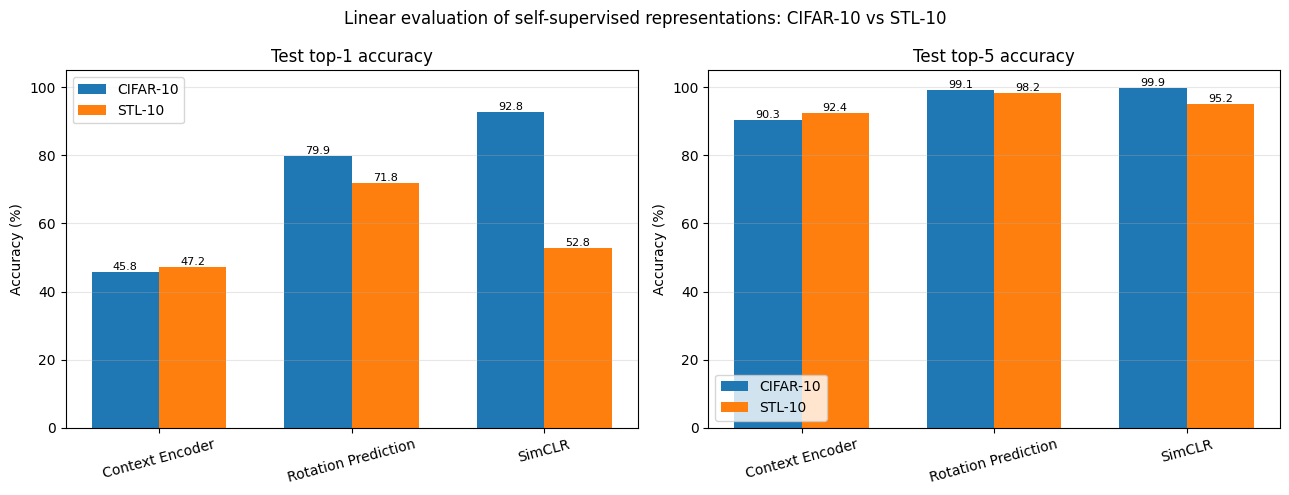

In [7]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

models = ['Context Encoder', 'Rotation Prediction', 'SimCLR']

# CIFAR-10: provided pre-trained models (outputs of the Demo 1-3 evaluation cells above)
cifar10 = {
    'Context Encoder':     {'train_top1': 53.236, 'train_top5': 94.094, 'test_top1': 45.77, 'test_top5': 90.29},
    'Rotation Prediction': {'train_top1': 79.41,  'train_top5': 99.1,   'test_top1': 79.91, 'test_top5': 99.12},
    'SimCLR':              {'train_top1': 89.938, 'train_top5': 99.444, 'test_top1': 92.84, 'test_top5': 99.86},
}
# STL-10: our pre-training + linear evaluation (results saved on Drive)
files = {'Context Encoder': 'stl10_context_encoder_results.json',
         'Rotation Prediction': 'stl10_rotation_results.json',
         'SimCLR': 'stl10_simclr_results.json'}
stl10 = {m: json.load(open(os.path.join(root_folder, f))) for m, f in files.items()}

# 1. Results table
rows = [{'Model': m, 'Dataset': ds, **res[m]}
        for m in models for ds, res in [('CIFAR-10', cifar10), ('STL-10', stl10)]]
df_all = pd.DataFrame(rows).set_index(['Model', 'Dataset'])
display(df_all.round(2))

# 2. Training budgets (needed to interpret the comparison)
protocol = pd.DataFrame({
    'CIFAR-10 (provided models)': {
        'Pre-training images': '50,000 (train set)',
        'Pre-training epochs / batch': 'Rotation: 200 / 128 (library defaults); SimCLR: 1000 / 512 (LARS, 4 GPUs); CE: not documented',
        'Labeled images (linear classifier)': '50,000',
        'Linear classifier': 'trained jointly with the pre-training'},
    'STL-10 (ours, 1 T4 GPU)': {
        'Pre-training images': '105,000 (5,000 train + 100,000 unlabeled, 32x32)',
        'Pre-training epochs / batch': 'Rotation: 10 / 128; CE: 10 / 128; SimCLR: 5 / 128 (SGD)',
        'Labeled images (linear classifier)': '5,000',
        'Linear classifier': '30 epochs on the frozen encoder'},
})
display(protocol)

# 3. Bar charts: test top-1 and top-5, CIFAR-10 vs STL-10
x = np.arange(len(models))
width = 0.35
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, metric, title in zip(axes, ['test_top1', 'test_top5'],
                                     ['Test top-1 accuracy', 'Test top-5 accuracy']):
    for k, (ds, res) in enumerate([('CIFAR-10', cifar10), ('STL-10', stl10)]):
        bars = ax.bar(x + (k - 0.5) * width, [res[m][metric] for m in models], width, label=ds)
        ax.bar_label(bars, fmt='%.1f', fontsize=8)
    #ax.axhline(chance, ls='--', c='gray', lw=1, label=f'Chance ({chance}%)')
    ax.set_title(title)
    ax.set_ylabel('Accuracy (%)')
    ax.set_xticks(x)
    ax.set_xticklabels(models, rotation=15)
    ax.set_ylim(0, 105)
    ax.legend()
    ax.grid(axis='y', alpha=0.3)

plt.suptitle('Linear evaluation of self-supervised representations: CIFAR-10 vs STL-10')
plt.tight_layout()
plt.savefig(os.path.join(root_folder, 'cifar10_vs_stl10_comparison.png'), dpi=300, bbox_inches='tight')
plt.show()

### Question 4: results and analysis

#### Results (linear evaluation, top-1 / top-5 accuracy in %)

| Model | CIFAR-10 train | CIFAR-10 test | STL-10 train | STL-10 test | Δ test top-1 (STL-10 − CIFAR-10) |
|---|---|---|---|---|---|
| Context Encoder | 53.2 / 94.1 | 45.8 / 90.3 | 95.2 / 99.8 | 47.2 / 92.4 | +1.4 |
| Rotation Prediction | 79.4 / 99.1 | 79.9 / 99.1 | 92.5 / 99.9 | **71.8** / 98.2 | −8.1 |
| SimCLR | 89.9 / 99.4 | **92.8** / 99.9 | 55.9 / 96.4 | 52.8 / 95.2 | −40.0 |

Pre-training time on STL-10 (one T4 GPU): rotation ≈ 43 min (10 epochs), context encoder ≈ 53 min (10 epochs), SimCLR ≈ 70 min (5 epochs).

#### 1. The ranking of the methods depends on the training budget

On CIFAR-10, with the provided models, the ranking is SimCLR > Rotation > Context Encoder, as reported in the literature. On STL-10, with our reduced budget, it becomes Rotation > SimCLR > Context Encoder. SimCLR loses 40 points of test top-1 accuracy, while rotation loses 8 points and the context encoder is stable.

This is consistent with the training budgets. The provided SimCLR model was trained for 1000 epochs with batches of 512 (LARS, 4 GPUs), against 5 epochs with batches of 128 here. Contrastive learning needs long training and many negatives (here 2 × 128 − 2 = 254 per view instead of 1022). Its pretext loss was still decreasing quickly when the training stopped (11.1 at initialisation, 8.7 after 4 epochs). Rotation prediction, on the contrary, already solves its pretext task well after 10 epochs (89% rotation accuracy) and gives a useful representation at a low cost.

With a comparable compute budget (about one hour on one GPU), rotation prediction gives the best representation on STL-10. SimCLR's advantage on CIFAR-10 should therefore be interpreted together with its much higher training cost.

#### 2. Overfitting versus underfitting of the linear classifier

On STL-10, the gap between train and test top-1 accuracy is very different across methods:
- **Context encoder: 95.2% vs 47.2% (gap of 48 points).** Strong overfitting: the library's transform for this task applies no data augmentation, so the linear classifier sees the same 5,000 images at every epoch and can memorise them with 4,000 features.
- **Rotation: 92.5% vs 71.8% (gap of 21 points).** Overfitting as well, with 12,288 features for 5,000 labeled images, but reduced by random crops and flips.
- **SimCLR: 55.9% vs 52.8% (gap of 3 points).** Underfitting: the classifier cannot even fit the training set, so the limit is the representation itself, which is not trained enough.

The CIFAR-10 train/test gaps are not directly comparable: the classifiers were trained on 50,000 labeled images, and the "train" accuracy is measured with the training augmentations in `load_model_and_data` (which explains why it can be lower than the test accuracy).

#### 3. The context encoder is the weakest representation on both datasets

Its test top-1 accuracy is below 50% on both datasets. Reconstructing pixels with an L2 loss mainly rewards low-level statistics (colours, smooth textures), not semantic content. In addition, the 32×32 images are upsampled to 128×128, so the masked region contains little detail, and the demo does not use the adversarial loss of the original paper. Its top-5 accuracy (> 90%) should be read relative to the chance level of 50% for 10 classes.

#### 4. Differences between CIFAR-10 and STL-10 beyond the budget

- **Fewer labels:** 5,000 labeled images on STL-10 versus 50,000 on CIFAR-10 for the linear classifier.
- **Resolution:** STL-10 images (96×96) were downsampled to 32×32 to use the CIFAR-10 architectures and transforms, which removes details.
- **Classes and distribution:** 9 of the 10 classes are shared (STL-10 has *monkey* instead of *frog*), and the 100,000 unlabeled STL-10 images come from a broader distribution than the labeled classes.

#### Limits of this comparison

- Pre-training budgets are not equal in epochs (10, 10 and 5) but are of the same order in GPU time; they are much smaller than those of the provided CIFAR-10 models.
- The linear classifier is trained after the pre-training, on the frozen encoder (CIFAR-10: trained jointly during pre-training).
- Each method uses the library's transforms for its own task during linear evaluation, so the augmentations differ (strong augmentations for SimCLR, none for the context encoder).
- Each result comes from a single run (no repetition with different seeds), so differences of a few points are not significant.
- No hyperparameter was tuned on the test set: the library defaults were used, and the test set was evaluated once per method.

## Relative patch position prediction (Doersch et al., 2015)

A 3x3 grid of 7x7 patches is cut from each 32x32 image, with a random grid origin, a random per-patch jitter and gaps of 2-4 pixels between neighbouring patches (to prevent trivial solutions based on continuing edges or textures across patch borders). For each of the 8 neighbours, the network predicts its position relative to the centre patch (8-way classification). Half of the patches are converted to grayscale to prevent the use of chromatic aberration (see Demo 5).

To isolate the effect of the pretext task, the encoder is the library's `NetworkInNetwork`, as for rotation prediction, and the representation used for linear evaluation is the same: `conv2` features of the full 32x32 image (192x8x8). The class follows the interface of the library's tasks, so the existing training and evaluation functions are reused unchanged.

In [9]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from deepul_helper.tasks.rotation import NetworkInNetwork


class RelativePatchPrediction(nn.Module):
    """Context prediction (Doersch et al., 2015) adapted to 32x32 images.
    Same interface as the library's tasks (metrics, forward, encode, construct_classifier)."""
    metrics = ['Loss', 'Acc1']
    metrics_fmt = [':.4e', ':6.2f']

    cell, patch = 10, 7                       # grid cell size and patch size (pixels)
    neighbours = [0, 1, 2, 3, 5, 6, 7, 8]     # grid positions around the centre (4); label = index in this list

    def __init__(self, dataset, n_classes, gray_prob=0.5):
        super().__init__()
        assert dataset == 'cifar10', "Designed for 32x32 images"
        self.model = NetworkInNetwork()       # same backbone as the library's rotation task
        self.feat_layer = 'conv2'
        self.latent_dim = 192 * 8 * 8         # conv2 features of a full 32x32 image (as for rotation)
        patch_dim = 192 * 2 * 2               # conv2 features of a 7x7 patch (7 -> 4 -> 2 after the two poolings)

        # Patch embedding (shared by all patches), then pair classifier (centre + neighbour -> 8 positions)
        self.patch_fc = nn.Sequential(nn.Linear(patch_dim, 256), nn.BatchNorm1d(256), nn.ReLU(inplace=True))
        self.pair_head = nn.Sequential(nn.Linear(2 * 256, 256), nn.BatchNorm1d(256), nn.ReLU(inplace=True),
                                       nn.Linear(256, 8))
        self.gray_prob = gray_prob
        self.dataset = dataset
        self.n_classes = n_classes

    def construct_classifier(self):
        # Same linear classifier as the library's rotation task (CIFAR-10 version)
        return nn.Sequential(nn.BatchNorm1d(self.latent_dim, affine=False),
                             nn.Linear(self.latent_dim, self.n_classes))

    def _extract_patches(self, images):
        """(B, 3, 32, 32) -> (B, 9, 3, 7, 7), grid positions in row-major order (centre = 4)."""
        B, dev = images.shape[0], images.device
        rows = torch.arange(3, device=dev).repeat_interleave(3)    # 0,0,0,1,1,1,2,2,2
        cols = torch.arange(3, device=dev).repeat(3)               # 0,1,2,0,1,2,0,1,2
        origin = torch.randint(0, 3, (B, 1, 2), device=dev)        # random grid origin: 0-2 px
        jitter = torch.randint(1, 3, (B, 9, 2), device=dev)        # per-patch jitter: 1-2 px -> gaps of 2-4 px
        top = origin[..., 0] + self.cell * rows + jitter[..., 0]   # (B, 9)
        left = origin[..., 1] + self.cell * cols + jitter[..., 1]  # (B, 9)
        offs = torch.arange(self.patch, device=dev)
        iy = (top[..., None] + offs)[:, :, :, None]                # (B, 9, 7, 1) row indices
        ix = (left[..., None] + offs)[:, :, None, :]               # (B, 9, 1, 7) column indices
        b = torch.arange(B, device=dev)[:, None, None, None]       # (B, 1, 1, 1) image indices
        patches = images[b, :, iy, ix]                             # (B, 9, 7, 7, 3)
        patches = patches.permute(0, 1, 4, 2, 3)                   # (B, 9, 3, 7, 7)

        if self.training and self.gray_prob > 0:                   # grayscale on half of the patches
            gray = patches.mean(dim=2, keepdim=True).expand_as(patches)
            mask = torch.rand(B, 9, 1, 1, 1, device=dev) < self.gray_prob
            patches = torch.where(mask, gray, patches)
        return patches

    def forward(self, images):
        B = images.shape[0]
        patches = self._extract_patches(images)                                  # (B, 9, 3, 7, 7)
        feats = self.model(patches.flatten(0, 1), out_feat_keys=(self.feat_layer,))   # (B*9, 192, 2, 2)
        feats = self.patch_fc(feats.flatten(1)).view(B, 9, -1)                   # (B, 9, 256)

        centre = feats[:, 4:5].expand(-1, 8, -1)                                 # (B, 8, 256)
        others = feats[:, self.neighbours]                                       # (B, 8, 256)
        logits = self.pair_head(torch.cat([centre, others], dim=2).flatten(0, 1))  # (B*8, 8)
        targets = torch.arange(8, device=images.device).repeat(B)                # labels 0..7 for each image

        loss = F.cross_entropy(logits, targets)
        acc = logits.argmax(dim=1).eq(targets).float().mean() * 100.

        # Full-image representation, only needed for linear evaluation (skipped during pre-training)
        zs = None if self.training else self.encode(images)
        return dict(Loss=loss, Acc1=acc), zs

    def encode(self, images):
        return self.model(images, out_feat_keys=(self.feat_layer,)).flatten(1)  # (B, 12288)

### Relative patch prediction: sanity checks

Check the output shapes, the initial loss (expected close to ln 8 ≈ 2.08 for 8 balanced classes) and visualise the extracted patches with their labels.

train mode | loss 2.134 (ln 8 = 2.079) | acc 11.7% | zs: None
eval mode  | zs shape (16, 12288) (expected (16, 12288))


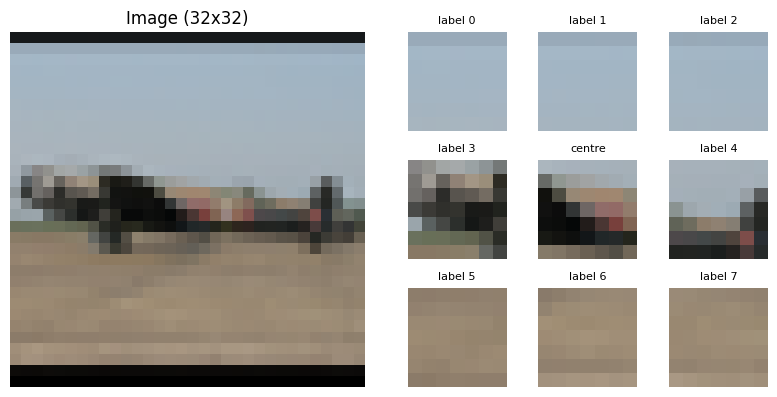

In [10]:
import matplotlib.pyplot as plt

device = 'cuda'
probe_set = STL10Wrapper(train_dataset, 'rotation', train=False)   # normalised 32x32 images, no augmentation
x = torch.stack([probe_set[i][0] for i in range(16)]).to(device)

patch_model = RelativePatchPrediction('cifar10', 10).to(device)

patch_model.train()
out, zs = patch_model(x)
print(f"train mode | loss {out['Loss'].item():.3f} (ln 8 = 2.079) | acc {out['Acc1'].item():.1f}% | zs: {zs}")

patch_model.eval()
with torch.no_grad():
    out, zs = patch_model(x)
    patches = patch_model._extract_patches(x[:1])[0].cpu()        # (9, 3, 7, 7), no grayscale in eval mode
print(f"eval mode  | zs shape {tuple(zs.shape)} (expected (16, 12288))")

# Visualisation: full image + the 9 patches with their label (position relative to the centre)
mean = torch.tensor([0.4914, 0.4822, 0.4465]).view(3, 1, 1)
std = torch.tensor([0.247, 0.243, 0.261]).view(3, 1, 1)
to_img = lambda t: (t.cpu() * std + mean).clamp(0, 1).permute(1, 2, 0)

fig = plt.figure(figsize=(8, 4))
ax = fig.add_subplot(1, 2, 1)
ax.imshow(to_img(x[0])); ax.set_title('Image (32x32)'); ax.axis('off')
for k in range(9):
    ax = fig.add_subplot(3, 6, 4 + (k // 3) * 6 + (k % 3))
    ax.imshow(to_img(patches[k]))
    ax.set_title('centre' if k == 4 else f'label {RelativePatchPrediction.neighbours.index(k)}', fontsize=8)
    ax.axis('off')
plt.tight_layout()
plt.show()

### Relative patch prediction: pre-training and linear evaluation functions

The STL-10 functions above are tied to the STL-10 wrappers; the patch task must also be pre-trained on CIFAR-10. `pretrain_on` and `linear_probe_on` contain exactly the same loops as `pretrain_stl10` and `linear_probe_stl10`, but take the datasets as arguments.

Pre-training transform: horizontal flip only. The rotation transform's `RandomCrop(32, padding=4)` is not used, because its black borders would reveal the position of the border patches (trivial shortcut). The linear evaluation uses the library's rotation transforms, as for rotation prediction.

In [11]:
import os
import time
import json
import numpy as np
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader, ConcatDataset
from torchvision import datasets, transforms
from deepul_helper.data import get_transform
from deepul_helper.demos import evaluate_classifier, images_to_cuda

device = 'cuda'

# Free the GPU from the SimCLR model (its results are saved on Drive)
for name in ['simclr_model', 'simclr_optimizer']:
    globals().pop(name, None)
torch.cuda.empty_cache()

# Pre-training transform for the patch task: flip only (no padded crop, see above)
patch_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.247, 0.243, 0.261))   # library's CIFAR-10 statistics
])


def pretrain_on(model, dataset, epochs, optimizer, ckpt_name, batch_size=128):
    """Same loop as pretrain_stl10, with the pre-training set given as an argument."""
    ckpt_path = os.path.join(root_folder, ckpt_name)
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=True,
                        num_workers=2, pin_memory=True, drop_last=True)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=0)
    start_epoch = 0

    if os.path.exists(ckpt_path):
        ckpt = torch.load(ckpt_path, map_location=device, weights_only=False)
        assert ckpt['epochs'] == epochs, "The checkpoint was made with a different number of epochs"
        model.load_state_dict(ckpt['model'])
        optimizer.load_state_dict(ckpt['optimizer'])
        scheduler.load_state_dict(ckpt['scheduler'])
        start_epoch = ckpt['epoch']
        print(f"Resuming from epoch {start_epoch}/{epochs}")

    for epoch in range(start_epoch, epochs):
        model.train()
        t0 = time.time()
        sums, n_iter = {k: 0.0 for k in model.metrics}, 0
        for images, _ in loader:                  # labels are ignored (self-supervised)
            images = images_to_cuda(images)
            out, _ = model(images)
            optimizer.zero_grad()
            out['Loss'].backward()
            optimizer.step()
            for k in model.metrics:
                sums[k] += out[k].item()
            n_iter += 1
        scheduler.step()

        log = ' | '.join(f"{k} {v / n_iter:.4f}" for k, v in sums.items())
        print(f"epoch {epoch + 1:3d}/{epochs} | {log} | {time.time() - t0:.0f} s")
        torch.save({'epoch': epoch + 1, 'epochs': epochs, 'model': model.state_dict(),
                    'optimizer': optimizer.state_dict(), 'scheduler': scheduler.state_dict()},
                   ckpt_path)
    return model


def linear_probe_on(model, train_set, eval_train_set, test_set, results_name,
                    probe_epochs=30, batch_size=128):
    """Same as linear_probe_stl10, with the datasets given as arguments."""
    model.eval()
    for p in model.parameters():
        p.requires_grad_(False)

    classifier = model.construct_classifier().to(device)
    optimizer = torch.optim.SGD(classifier.parameters(), lr=0.1, momentum=0.9, nesterov=True)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=probe_epochs, eta_min=0)

    train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True, num_workers=2, drop_last=True)
    eval_train_loader = DataLoader(eval_train_set, batch_size=batch_size, shuffle=False, num_workers=2)
    eval_test_loader = DataLoader(test_set, batch_size=batch_size, shuffle=False, num_workers=2)

    start = time.time()
    for epoch in range(probe_epochs):
        classifier.train()
        loss_sum, correct, total = 0.0, 0, 0
        for images, labels in train_loader:
            images, labels = images_to_cuda(images), labels.to(device)
            with torch.no_grad():
                _, zs = model(images)              # frozen encoder: features only
            logits = classifier(zs)
            loss = F.cross_entropy(logits, labels)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            loss_sum += loss.item() * labels.size(0)
            correct += (logits.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)
        scheduler.step()
        if epoch == 0 or (epoch + 1) % 5 == 0:
            print(f"probe epoch {epoch + 1:2d}/{probe_epochs} | loss {loss_sum / total:.3f} | "
                  f"train acc (train transforms) {100 * correct / total:.1f}%")
    print(f"Linear probing took {time.time() - start:.0f} s")

    classifier.eval()
    train_acc1, train_acc5 = evaluate_classifier(model, classifier, eval_train_loader)
    test_acc1, test_acc5 = evaluate_classifier(model, classifier, eval_test_loader)
    results = {'train_top1': train_acc1, 'train_top5': train_acc5,
               'test_top1': test_acc1, 'test_top5': test_acc5}
    with open(os.path.join(root_folder, results_name), 'w') as f:
        json.dump(results, f)
    return results


# Pre-training sets for the patch task
cifar_pretrain = datasets.CIFAR10('data/cifar10', train=True, transform=patch_transform, download=True)

if 'unlabeled_32' not in globals():
    unlabeled_32 = np.load(os.path.join(root_folder, 'stl10_unlabeled_32.npy'))
stl_labeled = STL10Wrapper(train_dataset, 'rotation', train=False)
stl_labeled.transform = patch_transform                  # same images, patch transform
stl_unlabeled = STL10UnlabeledWrapper(unlabeled_32, 'rotation', train=False)
stl_unlabeled.transform = patch_transform
stl_pretrain = ConcatDataset([stl_labeled, stl_unlabeled])   # same 105,000 images as the other methods

print("CIFAR-10 pre-training set:", len(cifar_pretrain))
print("STL-10 pre-training set:  ", len(stl_pretrain))

CIFAR-10 pre-training set: 50000
STL-10 pre-training set:   105000


### Relative patch prediction on CIFAR-10

Pre-training on the 50,000 CIFAR-10 train images (labels ignored), 10 epochs, library defaults (same as rotation on STL-10). Linear evaluation: 50,000 labeled train images, 10,000 test images, with the library's CIFAR-10 rotation transforms.

In [12]:
patch_cifar = RelativePatchPrediction('cifar10', 10).to(device)
patch_cifar_opt = torch.optim.SGD(patch_cifar.parameters(), lr=0.1, momentum=0.9,
                                  weight_decay=5e-4, nesterov=True)
patch_cifar = pretrain_on(patch_cifar, cifar_pretrain, 10, patch_cifar_opt,
                          ckpt_name='cifar10_patch_ckpt.pth')

epoch   1/10 | Loss 1.8097 | Acc1 30.3305 | 24 s
epoch   2/10 | Loss 1.7101 | Acc1 35.1427 | 21 s
epoch   3/10 | Loss 1.6761 | Acc1 36.6872 | 23 s
epoch   4/10 | Loss 1.6525 | Acc1 37.7434 | 21 s
epoch   5/10 | Loss 1.6317 | Acc1 38.6576 | 22 s
epoch   6/10 | Loss 1.6105 | Acc1 39.4444 | 21 s
epoch   7/10 | Loss 1.5897 | Acc1 40.3941 | 24 s
epoch   8/10 | Loss 1.5678 | Acc1 41.1969 | 21 s
epoch   9/10 | Loss 1.5497 | Acc1 42.0257 | 22 s
epoch  10/10 | Loss 1.5333 | Acc1 42.6815 | 21 s


In [13]:
cifar_train_aug = datasets.CIFAR10('data/cifar10', train=True, transform=get_transform('cifar10', 'rotation', train=True))
cifar_train_eval = datasets.CIFAR10('data/cifar10', train=True, transform=get_transform('cifar10', 'rotation', train=False))
cifar_test = datasets.CIFAR10('data/cifar10', train=False, transform=get_transform('cifar10', 'rotation', train=False))


In [14]:

accuracy_cifar10_patch = linear_probe_on(patch_cifar, cifar_train_aug, cifar_train_eval, cifar_test,
                                         results_name='cifar10_patch_results.json')
print("Relative patch prediction (CIFAR-10)")
print(accuracy_cifar10_patch)

probe epoch  1/30 | loss 27.181 | train acc (train transforms) 53.1%
probe epoch  5/30 | loss 26.038 | train acc (train transforms) 61.9%
probe epoch 10/30 | loss 21.933 | train acc (train transforms) 64.0%
probe epoch 15/30 | loss 16.378 | train acc (train transforms) 66.4%
probe epoch 20/30 | loss 10.798 | train acc (train transforms) 68.9%
probe epoch 25/30 | loss 7.166 | train acc (train transforms) 72.0%
probe epoch 30/30 | loss 5.931 | train acc (train transforms) 73.4%
Linear probing took 708 s
Relative patch prediction (CIFAR-10)
{'train_top1': 78.992, 'train_top5': 98.95, 'test_top1': 74.19, 'test_top5': 98.32}


### Relative patch prediction on CIFAR-10: longer pre-training (30 epochs)

The 10-epoch model had not converged (pretext accuracy still increasing by ~0.7 point per epoch) and one epoch takes ~22 s, so the pre-training is repeated from scratch for 30 epochs (new cosine schedule). Both results are reported.

In [15]:
patch_cifar30 = RelativePatchPrediction('cifar10', 10).to(device)
patch_cifar30_opt = torch.optim.SGD(patch_cifar30.parameters(), lr=0.1, momentum=0.9,
                                    weight_decay=5e-4, nesterov=True)
patch_cifar30 = pretrain_on(patch_cifar30, cifar_pretrain, 30, patch_cifar30_opt,
                            ckpt_name='cifar10_patch30_ckpt.pth')

epoch   1/30 | Loss 1.8075 | Acc1 30.3420 | 22 s
epoch   2/30 | Loss 1.7109 | Acc1 35.0363 | 21 s
epoch   3/30 | Loss 1.6797 | Acc1 36.5134 | 22 s
epoch   4/30 | Loss 1.6604 | Acc1 37.3695 | 21 s
epoch   5/30 | Loss 1.6443 | Acc1 37.9657 | 23 s
epoch   6/30 | Loss 1.6320 | Acc1 38.5507 | 21 s
epoch   7/30 | Loss 1.6229 | Acc1 38.9801 | 28 s
epoch   8/30 | Loss 1.6156 | Acc1 39.1937 | 24 s
epoch   9/30 | Loss 1.6073 | Acc1 39.5543 | 21 s
epoch  10/30 | Loss 1.6020 | Acc1 39.8029 | 23 s
epoch  11/30 | Loss 1.5952 | Acc1 40.1455 | 23 s
epoch  12/30 | Loss 1.5898 | Acc1 40.3668 | 22 s
epoch  13/30 | Loss 1.5839 | Acc1 40.5496 | 21 s
epoch  14/30 | Loss 1.5782 | Acc1 40.7384 | 22 s
epoch  15/30 | Loss 1.5722 | Acc1 41.0837 | 21 s
epoch  16/30 | Loss 1.5615 | Acc1 41.4406 | 22 s
epoch  17/30 | Loss 1.5555 | Acc1 41.7523 | 21 s
epoch  18/30 | Loss 1.5471 | Acc1 42.0713 | 22 s
epoch  19/30 | Loss 1.5378 | Acc1 42.4469 | 21 s
epoch  20/30 | Loss 1.5305 | Acc1 42.6390 | 22 s
epoch  21/30 | Loss 

In [19]:
accuracy_cifar10_patch30 = linear_probe_on(patch_cifar30, cifar_train_aug, cifar_train_eval, cifar_test,
                                           results_name='cifar10_patch30_results.json')
print("Relative patch prediction, 30 pre-training epochs (CIFAR-10)")
print(accuracy_cifar10_patch30)

probe epoch  1/30 | loss 25.874 | train acc (train transforms) 55.6%
probe epoch  5/30 | loss 25.376 | train acc (train transforms) 63.6%
probe epoch 10/30 | loss 21.364 | train acc (train transforms) 66.0%
probe epoch 15/30 | loss 16.005 | train acc (train transforms) 67.8%
probe epoch 20/30 | loss 10.547 | train acc (train transforms) 70.6%
probe epoch 25/30 | loss 7.033 | train acc (train transforms) 73.1%
probe epoch 30/30 | loss 5.796 | train acc (train transforms) 74.5%
Linear probing took 703 s
Relative patch prediction, 30 pre-training epochs (CIFAR-10)
{'train_top1': 80.116, 'train_top5': 99.096, 'test_top1': 75.54, 'test_top5': 98.55}


### Relative patch prediction on STL-10

Same pre-training set (105,000 images), same budget (10 epochs) and same linear evaluation (`linear_probe_stl10` with the rotation transforms) as rotation prediction on STL-10.

In [16]:
patch_stl = RelativePatchPrediction('cifar10', 10).to(device)
patch_stl_opt = torch.optim.SGD(patch_stl.parameters(), lr=0.1, momentum=0.9,
                                weight_decay=5e-4, nesterov=True)
patch_stl = pretrain_on(patch_stl, stl_pretrain, 10, patch_stl_opt,
                        ckpt_name='stl10_patch_ckpt.pth')

epoch   1/10 | Loss 1.7655 | Acc1 30.4395 | 47 s
epoch   2/10 | Loss 1.6915 | Acc1 33.9361 | 45 s
epoch   3/10 | Loss 1.6693 | Acc1 34.9790 | 46 s
epoch   4/10 | Loss 1.6522 | Acc1 35.7505 | 46 s
epoch   5/10 | Loss 1.6373 | Acc1 36.4086 | 45 s
epoch   6/10 | Loss 1.6227 | Acc1 37.0625 | 45 s
epoch   7/10 | Loss 1.6069 | Acc1 37.7556 | 45 s
epoch   8/10 | Loss 1.5867 | Acc1 38.6578 | 45 s
epoch   9/10 | Loss 1.5684 | Acc1 39.4777 | 45 s
epoch  10/10 | Loss 1.5519 | Acc1 40.2083 | 46 s


In [17]:
accuracy_stl10_patch = linear_probe_stl10(patch_stl, 'rotation', results_name='stl10_patch_results.json')
print("Relative patch prediction (STL-10)")
print(accuracy_stl10_patch)

probe epoch  1/30 | loss 18.882 | train acc (train transforms) 43.8%
probe epoch  5/30 | loss 26.354 | train acc (train transforms) 54.7%
probe epoch 10/30 | loss 21.175 | train acc (train transforms) 59.8%
probe epoch 15/30 | loss 15.087 | train acc (train transforms) 64.4%
probe epoch 20/30 | loss 10.113 | train acc (train transforms) 68.4%
probe epoch 25/30 | loss 7.184 | train acc (train transforms) 72.5%
probe epoch 30/30 | loss 6.124 | train acc (train transforms) 74.9%
Linear probing took 179 s
Relative patch prediction (STL-10)
{'train_top1': 81.86, 'train_top5': 99.5, 'test_top1': 65.2625, 'test_top5': 96.95}


Rndom test without pretraining over dataset

In [18]:
random_model = RelativePatchPrediction('cifar10', 10).to(device)   # never trained
accuracy_stl10_random = linear_probe_stl10(random_model, 'rotation', results_name='stl10_random_results.json')
print("Random (untrained) encoder (STL-10)")
print(accuracy_stl10_random)

probe epoch  1/30 | loss 8.801 | train acc (train transforms) 26.8%
probe epoch  5/30 | loss 7.141 | train acc (train transforms) 39.1%
probe epoch 10/30 | loss 5.988 | train acc (train transforms) 42.2%
probe epoch 15/30 | loss 4.127 | train acc (train transforms) 46.9%
probe epoch 20/30 | loss 2.561 | train acc (train transforms) 55.0%
probe epoch 25/30 | loss 1.794 | train acc (train transforms) 58.8%
probe epoch 30/30 | loss 1.501 | train acc (train transforms) 61.8%
Linear probing took 174 s
Random (untrained) encoder (STL-10)
{'train_top1': 69.38, 'train_top5': 98.12, 'test_top1': 49.875, 'test_top5': 93.7625}


## Question 6: comparison of the four pretext tasks on CIFAR-10 and STL-10

CIFAR-10: context encoder, rotation and SimCLR are the provided pre-trained models; relative patch prediction is trained by us (10 epochs, and 30 epochs if available). STL-10: all models are trained by us with the same pre-training set and linear evaluation. The random (untrained) encoder, if available, gives the baseline obtained without any pre-training.

train_top1  train_top5  test_top1  \
Model                            Dataset                                       
Context Encoder                  CIFAR-10       53.24       94.09      45.77   
                                 STL-10         95.24       99.82      47.21   
Rotation Prediction              CIFAR-10       79.41       99.10      79.91   
                                 STL-10         92.52       99.94      71.80   
SimCLR                           CIFAR-10       89.94       99.44      92.84   
                                 STL-10         55.86       96.42      52.82   
Relative Patch (10 ep.)          CIFAR-10       78.99       98.95      74.19   
                                 STL-10         81.86       99.50      65.26   
Relative Patch (30 ep.)          CIFAR-10       80.12       99.10      75.54   
Random encoder (no pre-training) STL-10         69.38       98.12      49.88   

                                           test_top5  
Model                            Dataset              
Context Encoder                  CIFAR-10      90.29  
                                 STL-10        92.38  
Rotation Prediction              CIFAR-10      99.12  
                                 STL-10        98.22  
SimCLR                           CIFAR-10      99.86  
                                 STL-10        95.24  
Relative Patch (10 ep.)          CIFAR-10      98.32  
                                 STL-10        96.95  
Relative Patch (30 ep.)          CIFAR-10      98.55  
Random encoder (no pre-training) STL-10        93.76

Dataset,CIFAR-10,STL-10
Model,,
Context Encoder,45.77,47.21
Rotation Prediction,79.91,71.80
SimCLR,92.84,52.82
Relative Patch (10 ep.),74.19,65.26
Relative Patch (30 ep.),75.54,NaN
Random encoder (no pre-training),NaN,49.88


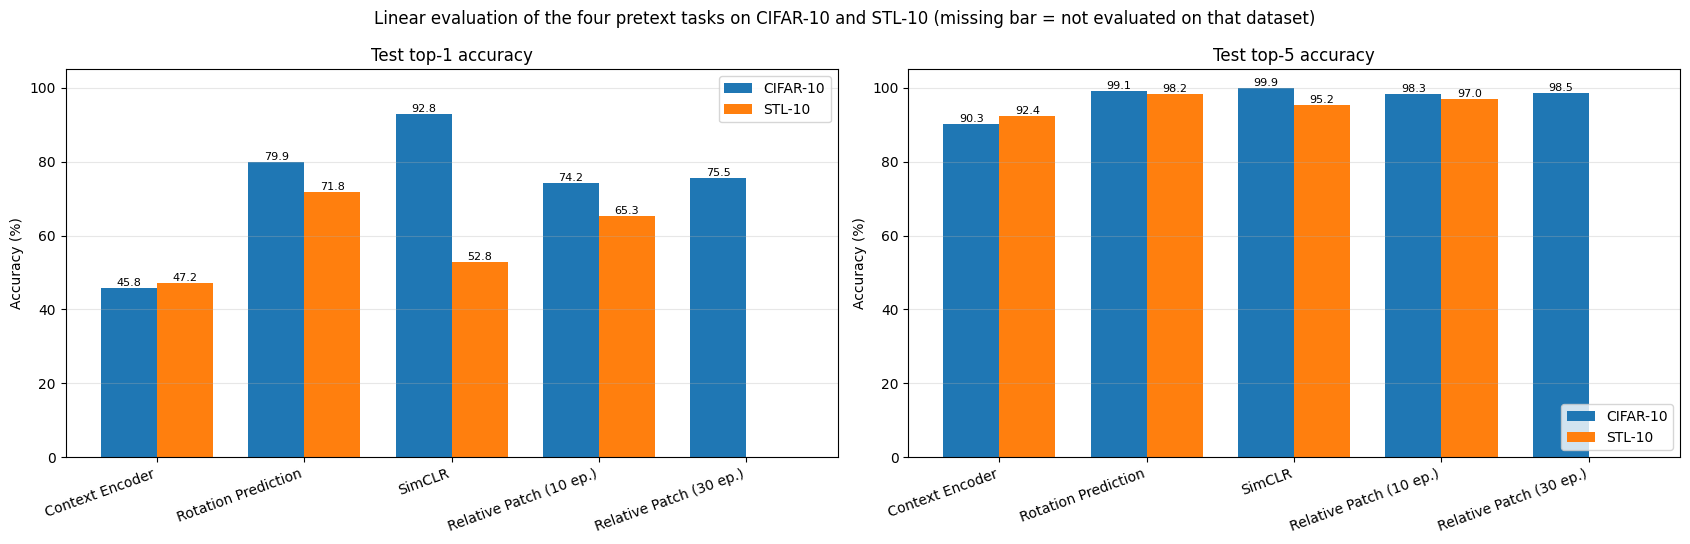

In [21]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

load = lambda f: json.load(open(os.path.join(root_folder, f)))
exists = lambda f: os.path.exists(os.path.join(root_folder, f))

# CIFAR-10: provided models (outputs of the Demo 1-3 cells) + our relative patch models
cifar10 = {
    'Context Encoder':     {'train_top1': 53.236, 'train_top5': 94.094, 'test_top1': 45.77, 'test_top5': 90.29},
    'Rotation Prediction': {'train_top1': 79.41,  'train_top5': 99.1,   'test_top1': 79.91, 'test_top5': 99.12},
    'SimCLR':              {'train_top1': 89.938, 'train_top5': 99.444, 'test_top1': 92.84, 'test_top5': 99.86},
    'Relative Patch (10 ep.)': load('cifar10_patch_results.json'),
}
if exists('cifar10_patch30_results.json'):
    cifar10['Relative Patch (30 ep.)'] = load('cifar10_patch30_results.json')

# STL-10: all models trained by us
stl10 = {
    'Context Encoder':     load('stl10_context_encoder_results.json'),
    'Rotation Prediction': load('stl10_rotation_results.json'),
    'SimCLR':              load('stl10_simclr_results.json'),
    'Relative Patch (10 ep.)': load('stl10_patch_results.json'),
}
if exists('stl10_random_results.json'):
    stl10['Random encoder (no pre-training)'] = load('stl10_random_results.json')

# Full table (train/test, top-1/top-5)
methods = list(dict.fromkeys(list(cifar10) + list(stl10)))
rows = [{'Model': m, 'Dataset': ds, **res[m]}
        for m in methods for ds, res in [('CIFAR-10', cifar10), ('STL-10', stl10)] if m in res]
df_q6 = pd.DataFrame(rows).set_index(['Model', 'Dataset'])
display(df_q6.round(2))

# Test top-1 summary (one row per method, one column per dataset)
summary = df_q6['test_top1'].unstack('Dataset').reindex(methods)
display(summary.round(2))


# Bar charts of test top-1 and top-5 accuracy, CIFAR-10 vs STL-10
#    (the random encoder baseline is reported in the tables only)
plot_methods = [m for m in methods if not m.startswith('Random')]
x = np.arange(len(plot_methods))
width = 0.38
fig, axes = plt.subplots(1, 2, figsize=(17, 5.5))
for ax, metric, title in zip(axes, ['test_top1', 'test_top5'],
                             ['Test top-1 accuracy', 'Test top-5 accuracy']):
    table = df_q6[metric].unstack('Dataset').reindex(plot_methods)
    for k, ds in enumerate(['CIFAR-10', 'STL-10']):
        vals = table[ds].values
        bars = ax.bar(x + (k - 0.5) * width, np.nan_to_num(vals), width, label=ds)
        ax.bar_label(bars, labels=['' if np.isnan(v) else f'{v:.1f}' for v in vals], fontsize=8)
    ax.set_title(title)
    ax.set_ylabel('Accuracy (%)')
    ax.set_xticks(x)
    ax.set_xticklabels(plot_methods, rotation=20, ha='right')
    ax.set_ylim(0, 105)
    ax.legend()
    ax.grid(axis='y', alpha=0.3)

plt.suptitle('Linear evaluation of the four pretext tasks on CIFAR-10 and STL-10 '
             '(missing bar = not evaluated on that dataset)')
plt.tight_layout()
plt.savefig(os.path.join(root_folder, 'q6_comparison.png'), dpi=300, bbox_inches='tight')
plt.show()

### Question 6: results and analysis

#### Results (linear evaluation, test top-1 accuracy, %)

| Model | CIFAR-10 | STL-10 | STL-10 gain over random NIN |
|---|---|---|---|
| Context Encoder | 45.8 (provided) | 47.2 | −2.7 (different architecture) |
| Rotation Prediction | 79.9 (provided, 200 ep.) | **71.8** (10 ep.) | **+21.9** |
| SimCLR | **92.8** (provided, 1000 ep.) | 52.8 (5 ep.) | +2.9 (different architecture) |
| **Relative Patch (ours)** | **74.2** (10 ep.) / **75.5** (30 ep.) | **65.3** (10 ep.) | **+15.4** |
| Random NIN encoder (no pre-training) | — | 49.9 | 0 |

Pre-training time of the relative patch task on one T4 GPU: ≈ 22 s per epoch on CIFAR-10 (≈ 4 min for 10 epochs, ≈ 11 min for 30) and ≈ 46 s per epoch on STL-10 (≈ 8 min for 10 epochs), against ≈ 258 s per epoch for rotation on STL-10 with the same encoder.

Top-5 accuracy is above 90% for all methods (chance level: 50% with 10 classes), so it discriminates poorly between them; the analysis relies on top-1 accuracy.

#### 1. The relative patch task learns a useful representation

The pretext task is learned: after 10 epochs, the network predicts the relative position of a patch with 42.7% accuracy on CIFAR-10 and 40.2% on STL-10, against 12.5% for chance (8 positions), and this accuracy was still increasing.

The resulting representation clearly outperforms the context encoder on both datasets (+28.4 points on CIFAR-10, +18.1 on STL-10). The random encoder baseline shows that this gain comes from the pre-training: with exactly the same encoder, representation and linear evaluation, the relative patch pre-training improves the STL-10 test accuracy by 15.4 points over an untrained network.

#### 2. Relative patch versus rotation: the most controlled comparison

Both tasks use the same encoder (`NetworkInNetwork`), the same representation (`conv2` features of the full 32×32 image, 12,288 dimensions) and the same linear evaluation, so the difference comes from the pretext task only.

- On STL-10, with the same pre-training set and the same number of epochs, rotation is ahead by 6.5 points (+21.9 vs +15.4 over the random encoder).
- On CIFAR-10, the relative patch model is 5.7 points below the provided rotation model after 10 epochs, and 4.4 points below after 30 epochs, while the rotation model was trained for 200 epochs.

The relative patch task is, however, much cheaper: about 5.6 times faster per epoch on STL-10 (46 s vs 258 s). It processes 9 patches of 7×7 pixels per image (441 pixels), while rotation processes 4 full 32×32 images (4,096 pixels). Our comparison is at equal number of epochs; at equal GPU time, the relative patch task could be trained much longer, but Section 3 suggests that this would bring limited gains.

#### 3. Longer pre-training brings little improvement

Tripling the pre-training on CIFAR-10 (30 epochs instead of 10) only increases the test top-1 accuracy from 74.2% to 75.5% (+1.4 points). With a single run per model, this difference is within the range of run-to-run variation, so we can only conclude that the returns of longer pre-training are strongly diminishing for this task. This contrasts with SimCLR, whose accuracy strongly depends on the training budget (92.8% after 1000 epochs on CIFAR-10, 52.8% after 5 epochs on STL-10, see Question 4).

#### 4. Relative patch task limitations on 32×32 images size

- **Very small patches:** the 7×7 patches (versus 96×96 in Doersch et al.) often contain uniform regions, such as sky or ground. Their relative position cannot be inferred, at least horizontally, as shown in the patch visualisation. Part of the pretext errors is therefore unavoidable, which plausibly limits what the network can learn and would explain the small gain of longer pre-training.
- **Scale mismatch:** the encoder is trained on 7×7 patches but evaluated on full 32×32 images, and its batch normalisation statistics are estimated on patches.
- **Remaining shortcuts:** gaps of 2-4 pixels, random jitter and random grayscale reduce trivial solutions, but some STL-10 images have black borders that could reveal the position of border patches.

#### 5. Consistency across datasets

The ranking Rotation > Relative Patch > Context Encoder is the same on CIFAR-10 and STL-10. Only SimCLR changes position, because of its much smaller training budget on STL-10 (Question 4). All methods lose accuracy on STL-10 except the context encoder: STL-10 offers 10 times fewer labeled images for the linear classifier (5,000 vs 50,000), and its images were downsampled from 96×96 to 32×32. Consistently, the train/test gap of the relative patch model is much larger on STL-10 (16.6 points) than on CIFAR-10 (4.8 points).

#### 6. The random encoder baseline

An untrained NIN encoder already reaches 49.9% on STL-10. Random convolutional filters capture colours and edges, and the 12,288-dimensional `conv2` map keeps spatial information that a linear classifier can exploit. Linear evaluation alone therefore overestimates the contribution of a pretext task, and the gain over this baseline is a better measure. This baseline is only valid for the NIN-based models (rotation, relative patch): the context encoder and SimCLR use other architectures, whose random versions were not evaluated, so we cannot conclude that the context encoder is worse than an untrained network.

#### Conclusion

The relative patch task, implemented on top of the library's interface, learns a useful representation at a very low cost (a few minutes on one GPU). It ranks second among the four pretext tasks on STL-10 and third on CIFAR-10, behind rotation prediction with the same encoder, and well ahead of the context encoder. On 32×32 images, its main limit seems to be the small size of the patches rather than the training length.

#### Limits

- Single run per model (no repetition with different seeds): differences of a few points are not significant.
- Short pre-training (10 epochs, 30 for one CIFAR-10 model), much shorter than for the provided CIFAR-10 models.
- Random baseline evaluated on STL-10 only, and for the NIN architecture only.
- The linear classifier is trained after the pre-training, on the frozen encoder; for the provided CIFAR-10 models, it was trained jointly with the pre-training.

In [22]:
import numpy as np
from torch.utils.data import Subset

# 5,000 CIFAR-10 labeled images (500 per class), as many as in STL-10
targets = np.array(cifar_train_aug.targets)
rng = np.random.default_rng(0)
idx = np.concatenate([rng.choice(np.where(targets == c)[0], 500, replace=False) for c in range(10)])

accuracy_cifar10_patch_5k = linear_probe_on(patch_cifar, Subset(cifar_train_aug, idx), Subset(cifar_train_eval, idx),
                                            cifar_test, results_name='cifar10_patch_5k_labels_results.json')
print("Relative patch (10 ep.), linear classifier trained on 5,000 CIFAR-10 labels")
print(accuracy_cifar10_patch_5k)

probe epoch  1/30 | loss 19.324 | train acc (train transforms) 43.3%
probe epoch  5/30 | loss 23.723 | train acc (train transforms) 56.6%
probe epoch 10/30 | loss 18.562 | train acc (train transforms) 62.7%
probe epoch 15/30 | loss 13.699 | train acc (train transforms) 67.3%
probe epoch 20/30 | loss 9.017 | train acc (train transforms) 70.5%
probe epoch 25/30 | loss 6.316 | train acc (train transforms) 75.4%
probe epoch 30/30 | loss 5.421 | train acc (train transforms) 75.9%
Linear probing took 77 s
Relative patch (10 ep.), linear classifier trained on 5,000 CIFAR-10 labels
{'train_top1': 83.7, 'train_top5': 99.34, 'test_top1': 66.8, 'test_top5': 97.12}


Test top-1 accuracy is higher on CIFAR-10 than on STL-10 for three of the four methods (not for the context encoder). This does not mean that CIFAR-10 is intrinsically easier: the two columns differ in pre-training budget (provided models trained for 200-1000 epochs on CIFAR-10), in the number of labeled images for the linear classifier (50,000 vs 5,000), in resolution (STL-10 downsampled from 96×96 to 32×32) and in data.

To isolate the effect of the number of labels, the CIFAR-10 relative patch model (10 epochs) was also evaluated with a linear classifier trained on 5,000 CIFAR-10 images only (500 per class, as in STL-10). Its test top-1 accuracy drops from 74.2% to 66.8%, close to the 65.3% obtained on STL-10, and its train/test gap rises from 4.8 to 16.9 points (16.6 on STL-10). The smaller number of labeled images therefore explains most of the 8.9-point difference between the two datasets for this method; the remaining 1.5 points are within the variation expected from a single run and a single random subset.

à nombre d’étiquettes égal, les deux datasets donnent des résultats proches.